# Recurrent Neural Networks (RNNs): Understanding Sequential Learning

Welcome to this comprehensive tutorial on Recurrent Neural Networks, the foundation of modern sequence modeling in machine learning.

## What You'll Learn
- **What are RNNs** and why they're essential for sequential data
- **Mathematical foundations** of recurrent architectures
- **Hands-on implementation** with PyTorch
- **LSTM & GRU** architectures and when to use them
- **Hospital demand forecasting** - predicting daily emergency department arrivals
- **Interactive parameter exploration** with widgets
- **Model interpretation** and visualization techniques
- **Performance comparisons** across architectures
- **Real-world best practices**

> **A note on the data.** The arrival counts in this notebook are simulated from
> published patterns of emergency department demand. They contain no real or
> identifiable patient information.

---


## 1. Introduction & Setup

First, let's import all necessary libraries and check versions to ensure everything is working correctly.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# PyTorch for neural networks
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Version checks
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")

NumPy version: 2.5.3
Pandas version: 3.0.6
PyTorch version: 2.14.1
Using device: cpu


### What are Recurrent Neural Networks?

**Recurrent Neural Networks (RNNs)** are neural networks designed to work with **sequential data** by maintaining an internal state (memory) that captures information about previous inputs.

#### Key Characteristics:
1. **Memory**: RNNs have internal state that persists across time steps
2. **Parameter Sharing**: Same weights are used across all time steps
3. **Variable-Length Input**: Can handle sequences of different lengths
4. **Temporal Dependencies**: Captures relationships across time

#### Common Applications:
- ✅ **Time Series Forecasting**: Stock prices, weather, sensor data
- ✅ **Natural Language Processing**: Machine translation, text generation
- ✅ **Speech Recognition**: Converting audio to text
- ✅ **Video Analysis**: Action recognition, captioning
- ✅ **Healthcare Operations**: Emergency department demand, bed occupancy, staffing, bedside vital-sign trends

#### When to Use RNNs:
- ✅ Data has temporal or sequential structure
- ✅ Past information influences future predictions
- ✅ Variable-length sequences
- ❌ Data is tabular with no temporal relationship → use XGBoost, Random Forest
- ❌ Very long sequences (>1000 steps) → consider Transformers instead


---
## 2. Understanding Sequential Data & RNN Fundamentals

Let's start by understanding how RNNs process sequential data differently from traditional neural networks.

### Traditional Neural Network vs RNN

**Traditional (Feedforward) Neural Network:**
```
Input → Hidden Layer → Output
```
- Processes each input independently
- No memory of previous inputs
- Fixed input/output size

**Recurrent Neural Network:**
```
Input[t] + Hidden[t-1] → Hidden[t] → Output[t]
```
- Uses previous hidden state as additional input
- Maintains memory across time steps
- Can handle variable-length sequences

### RNN Mathematics

At each time step t, an RNN computes:

**Hidden State Update:**
```
h[t] = tanh(W_hh * h[t-1] + W_xh * x[t] + b_h)
```

**Output:**
```
y[t] = W_hy * h[t] + b_y
```

Where:
- `h[t]` = hidden state at time t (the memory)
- `x[t]` = input at time t
- `y[t]` = output at time t
- `W_hh, W_xh, W_hy` = weight matrices (shared across time)
- `b_h, b_y` = bias terms
- `tanh` = activation function (squashes values between -1 and 1)

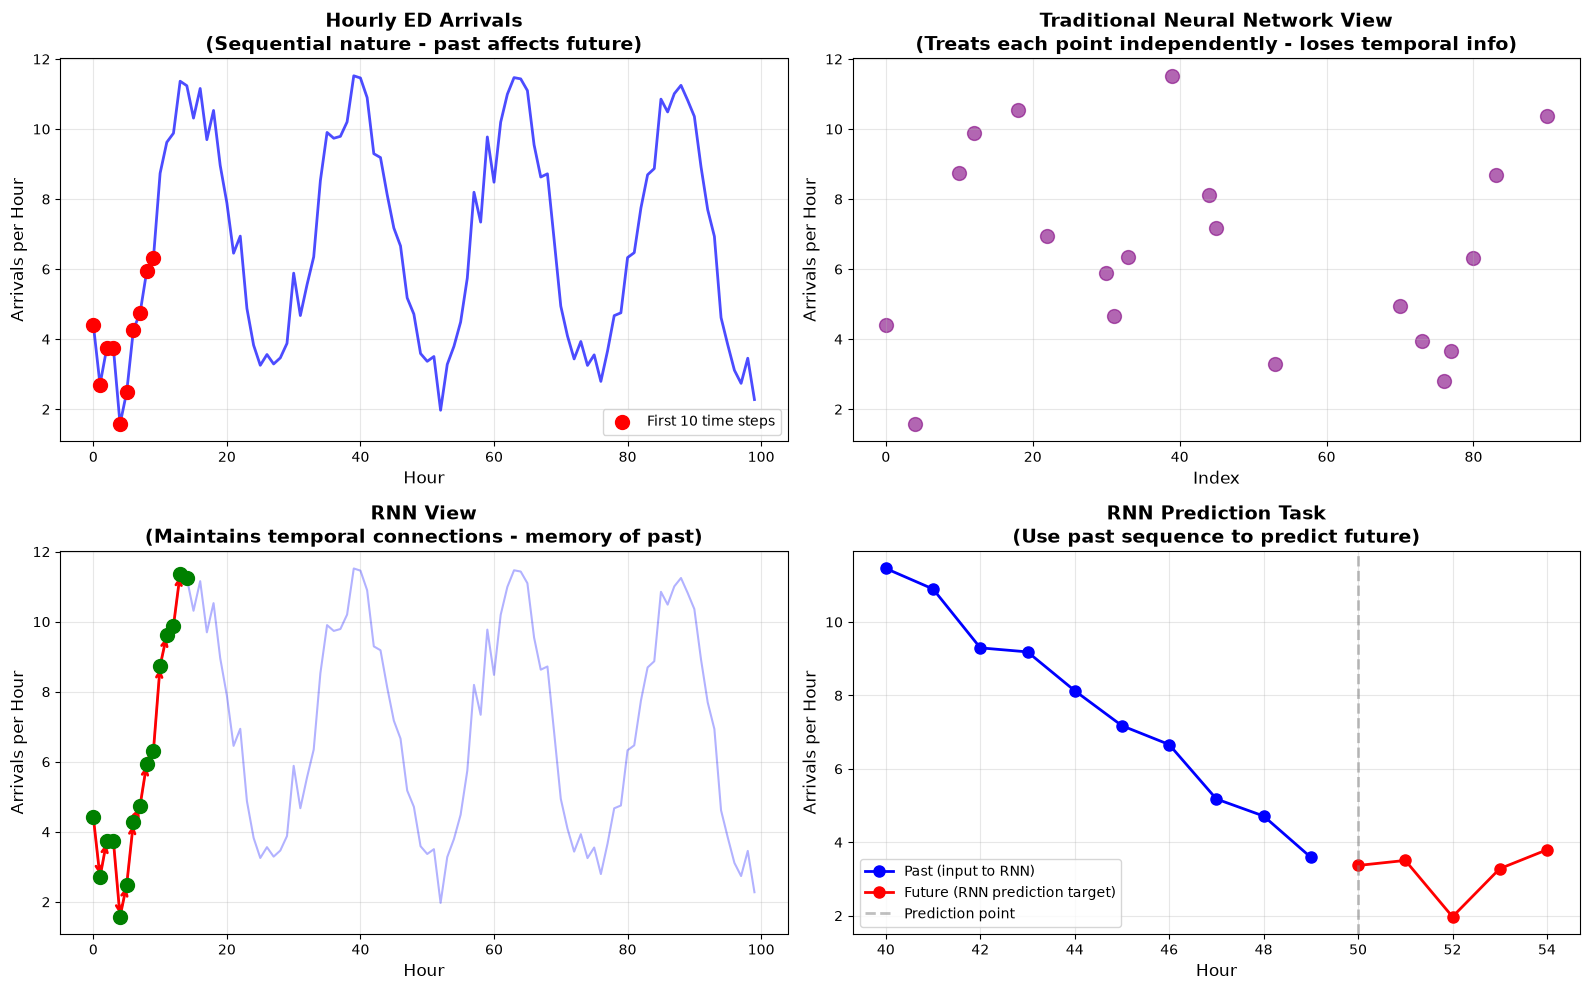

KEY INSIGHTS:
  - Sequential data has temporal dependencies - order matters!
  - Traditional NNs lose this temporal information
  - RNNs maintain 'memory' of previous time steps
  - This memory allows prediction of future values based on past patterns


In [2]:
# Visualize how RNNs process sequential data
# Create a simple sequence: hourly arrivals at an emergency department.
# ED demand has a strong daily rhythm - quiet overnight, busy from mid-morning
# through the evening - so it is a natural sequence to reason about.
time_steps = 100
rng_demo = np.random.default_rng(42)
t = np.arange(time_steps)            # hours since midnight on day 1
hour_of_day = t % 24
arrivals_sequence = 7 + 4 * np.sin(2 * np.pi * (hour_of_day - 9) / 24) \
                    + rng_demo.normal(0, 0.8, time_steps)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Sequential data visualization
axes[0, 0].plot(t, arrivals_sequence, 'b-', alpha=0.7, linewidth=2)
axes[0, 0].scatter(t[:10], arrivals_sequence[:10], c='red', s=100, zorder=5, label='First 10 time steps')
axes[0, 0].set_xlabel('Hour', fontsize=12)
axes[0, 0].set_ylabel('Arrivals per Hour', fontsize=12)
axes[0, 0].set_title('Hourly ED Arrivals\n(Sequential nature - past affects future)', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. How traditional NN sees the data (independent points)
sample_indices = np.random.choice(time_steps, 20, replace=False)
axes[0, 1].scatter(sample_indices, arrivals_sequence[sample_indices], c='purple', s=100, alpha=0.6)
axes[0, 1].set_xlabel('Index', fontsize=12)
axes[0, 1].set_ylabel('Arrivals per Hour', fontsize=12)
axes[0, 1].set_title('Traditional Neural Network View\n(Treats each point independently - loses temporal info)',
                     fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# 3. How RNN sees the data (connected sequence)
axes[1, 0].plot(t, arrivals_sequence, 'b-', alpha=0.3)
for i in range(1, 15):
    axes[1, 0].annotate('', xy=(t[i], arrivals_sequence[i]), xytext=(t[i-1], arrivals_sequence[i-1]),
                        arrowprops=dict(arrowstyle='->', color='red', lw=2))
axes[1, 0].scatter(t[:15], arrivals_sequence[:15], c='green', s=100, zorder=5)
axes[1, 0].set_xlabel('Hour', fontsize=12)
axes[1, 0].set_ylabel('Arrivals per Hour', fontsize=12)
axes[1, 0].set_title('RNN View\n(Maintains temporal connections - memory of past)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 4. Prediction task: use past to predict future
lookback = 10
predict_idx = 50
axes[1, 1].plot(t[predict_idx-lookback:predict_idx], arrivals_sequence[predict_idx-lookback:predict_idx],
                'b-o', linewidth=2, markersize=8, label='Past (input to RNN)')
axes[1, 1].plot(t[predict_idx:predict_idx+5], arrivals_sequence[predict_idx:predict_idx+5],
                'r-o', linewidth=2, markersize=8, label='Future (RNN prediction target)')
axes[1, 1].axvline(x=t[predict_idx], color='gray', linestyle='--', linewidth=2, alpha=0.5, label='Prediction point')
axes[1, 1].set_xlabel('Hour', fontsize=12)
axes[1, 1].set_ylabel('Arrivals per Hour', fontsize=12)
axes[1, 1].set_title('RNN Prediction Task\n(Use past sequence to predict future)', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("KEY INSIGHTS:")
print("  - Sequential data has temporal dependencies - order matters!")
print("  - Traditional NNs lose this temporal information")
print("  - RNNs maintain 'memory' of previous time steps")
print("  - This memory allows prediction of future values based on past patterns")


---
## 3. Vanilla RNN Implementation

Let's implement a basic RNN from scratch to understand how it works, then use PyTorch's built-in RNN.

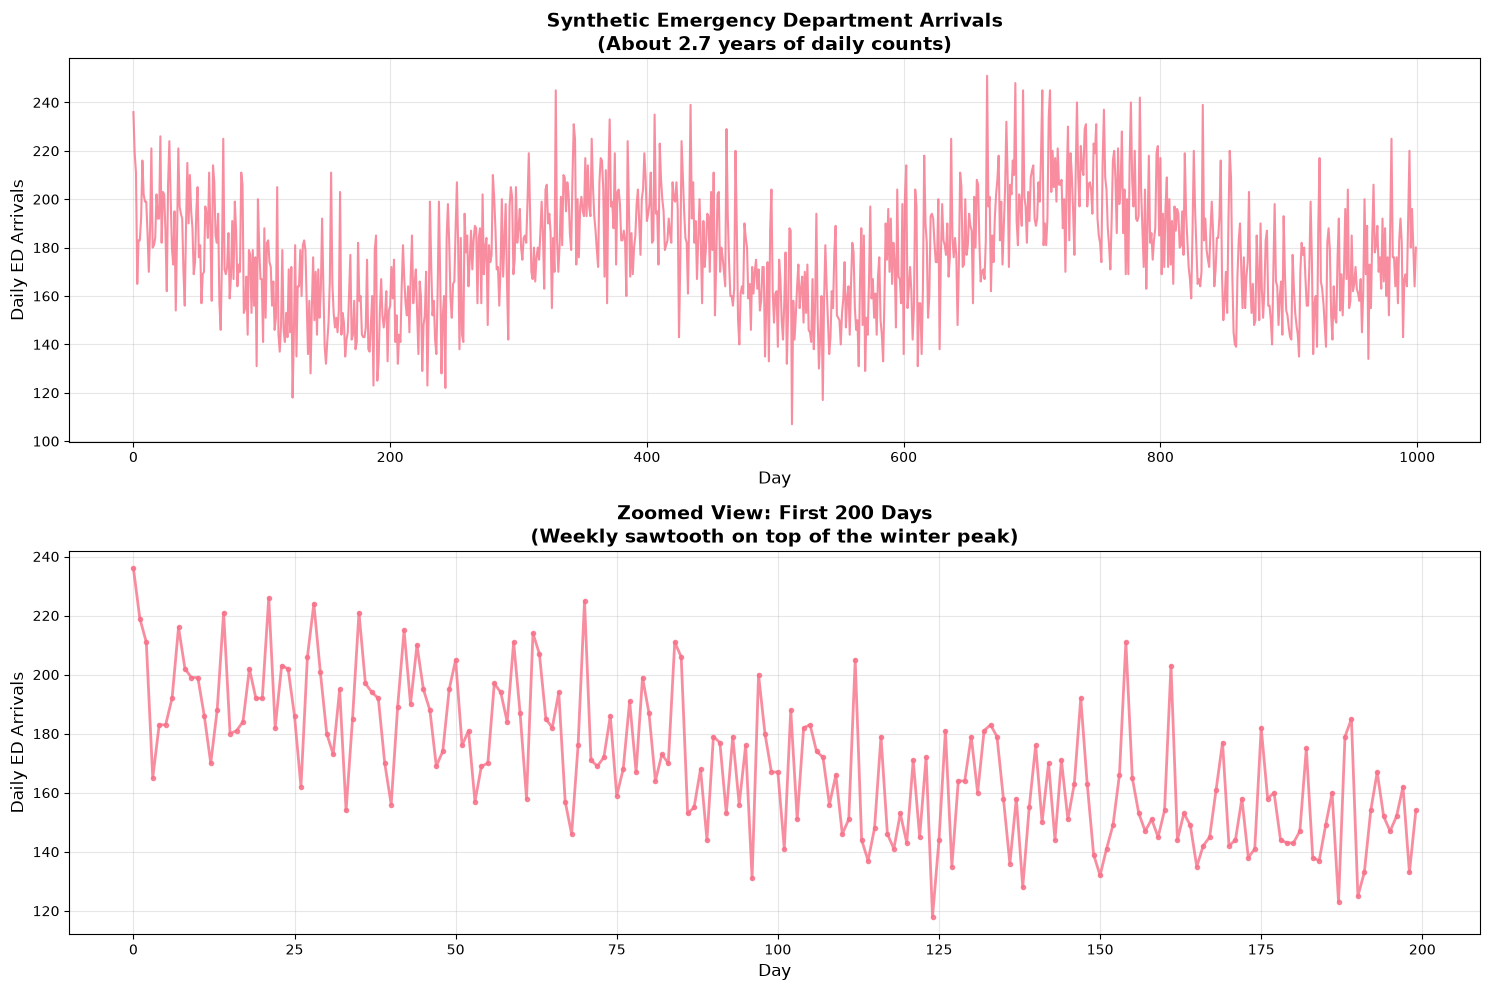

Dataset Statistics:
  - Total days: 1000
  - Mean arrivals/day: 177.9
  - Std deviation: 24.2
  - Quietest day: 107
  - Busiest day: 251

Mean arrivals by day of week:
  - Mon: 201.9
  - Tue: 182.7
  - Wed: 174.0
  - Thu: 169.3
  - Fri: 175.7
  - Sat: 161.8
  - Sun: 180.3


In [3]:
# Create synthetic emergency department arrival counts
def generate_ed_arrivals_data(n_samples=1000, noise_level=1.0, seed=42):
    """
    Generate synthetic daily arrival counts for a mid-size emergency department.

    Real ED demand is the sum of a few very regular rhythms:
    - A weekly cycle. Monday is the busiest day of the week almost everywhere,
      because problems that started over the weekend present once the week
      begins. Attendances fall away through the week and drop on Saturday.
    - An annual cycle. Winter respiratory season drives the yearly peak.
    - A slow upward trend, as the catchment population grows and ages.
    - Day-to-day randomness. Arrivals are counts of independent events, so the
      noise is Poisson-shaped: proportionally larger on quiet days.

    Day 0 is taken to be a Monday, 1 January.

    The counts are simulated. They contain no real or identifiable patient
    information.
    """
    rng = np.random.default_rng(seed)
    day = np.arange(n_samples)

    # Baseline attendance for a mid-size hospital
    baseline = 170.0

    # Slow growth in the catchment population
    trend = 0.015 * day

    # Annual cycle: peak in mid-winter (day 0 = 1 January), trough in summer
    annual = 22 * np.cos(2 * np.pi * day / 365.25)

    # Weekly cycle, Monday through Sunday
    weekday_effect = np.array([26, 6, -2, -6, -2, -14, 4])
    weekly = weekday_effect[day % 7]

    expected = baseline + trend + annual + weekly

    # Arrivals are counts of independent events -> Poisson
    arrivals = rng.poisson(expected).astype(float)

    # A little extra over-dispersion: weather, local events, a flu spike
    arrivals += noise_level * rng.normal(0, 4, n_samples)

    # No real ED sees fewer than ~100 or more than ~320 in a day
    return np.clip(np.round(arrivals), 100, 320)

# Generate data
arrivals_data = generate_ed_arrivals_data(n_samples=1000)

# Visualize
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))

# Full time series
ax1.plot(arrivals_data, linewidth=1.5, alpha=0.8)
ax1.set_xlabel('Day', fontsize=12)
ax1.set_ylabel('Daily ED Arrivals', fontsize=12)
ax1.set_title('Synthetic Emergency Department Arrivals\n(About 2.7 years of daily counts)',
              fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Zoomed in view
zoom_range = slice(0, 200)
ax2.plot(arrivals_data[zoom_range], linewidth=2, alpha=0.8, marker='o', markersize=3)
ax2.set_xlabel('Day', fontsize=12)
ax2.set_ylabel('Daily ED Arrivals', fontsize=12)
ax2.set_title('Zoomed View: First 200 Days\n(Weekly sawtooth on top of the winter peak)',
              fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Dataset Statistics:")
print(f"  - Total days: {len(arrivals_data)}")
print(f"  - Mean arrivals/day: {np.mean(arrivals_data):.1f}")
print(f"  - Std deviation: {np.std(arrivals_data):.1f}")
print(f"  - Quietest day: {np.min(arrivals_data):.0f}")
print(f"  - Busiest day: {np.max(arrivals_data):.0f}")

# Confirm the weekly rhythm is really there
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
print(f"\nMean arrivals by day of week:")
for k, name in enumerate(day_names):
    print(f"  - {name}: {arrivals_data[k::7].mean():.1f}")


In [4]:
# Prepare data for RNN training
def create_sequences(data, sequence_length):
    """
    Create input-output pairs for sequence prediction
    
    Example: if sequence_length=10
    - Input: days 0-9
    - Output: day 10
    """
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i + sequence_length])
        y.append(data[i + sequence_length])
    return np.array(X), np.array(y)

# Normalize data (RNNs work better with normalized inputs)
scaler = MinMaxScaler(feature_range=(-1, 1))
arrivals_normalized = scaler.fit_transform(arrivals_data.reshape(-1, 1)).flatten()

# Create sequences
sequence_length = 20  # Use past 20 days to predict next day
X, y = create_sequences(arrivals_normalized, sequence_length)

# Train/test split (80/20)
split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train).unsqueeze(-1)  # Shape: (batch, seq_len, input_size)
y_train_tensor = torch.FloatTensor(y_train).unsqueeze(-1)
X_test_tensor = torch.FloatTensor(X_test).unsqueeze(-1)
y_test_tensor = torch.FloatTensor(y_test).unsqueeze(-1)

print(f"📦 Data Preparation Complete:")
print(f"  • Sequence length: {sequence_length} days")
print(f"  • Training samples: {len(X_train)}")
print(f"  • Test samples: {len(X_test)}")
print(f"  • X_train shape: {X_train_tensor.shape} (batch, sequence, features)")
print(f"  • y_train shape: {y_train_tensor.shape}")
print(f"\n📝 Example:")
print(f"  • Input: arrivals on days 0-{sequence_length-1}")
print(f"  • Output: arrivals on day {sequence_length}")
print(f"  • First input sequence: {X_train[0][:5]} ... (first 5 values)")
print(f"  • First target: {y_train[0]}")

📦 Data Preparation Complete:
  • Sequence length: 20 days
  • Training samples: 784
  • Test samples: 196
  • X_train shape: torch.Size([784, 20, 1]) (batch, sequence, features)
  • y_train shape: torch.Size([784, 1])

📝 Example:
  • Input: arrivals on days 0-19
  • Output: arrivals on day 20
  • First input sequence: [ 0.79166667  0.55555556  0.44444444 -0.19444444  0.05555556] ... (first 5 values)
  • First target: 0.1805555555555558


In [5]:
# Define a simple RNN model
class SimpleRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1, output_size=1):
        super(SimpleRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # RNN layer
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True  # Input shape: (batch, seq_len, input_size)
        )
        
        # Fully connected layer to produce output
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        # Initialize hidden state with zeros
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        # Forward propagate RNN
        # out: (batch, seq_len, hidden_size)
        # hn: (num_layers, batch, hidden_size) - final hidden state
        out, hn = self.rnn(x, h0)
        
        # We only care about the last time step's output
        # out[:, -1, :] takes the last time step for each batch
        out = self.fc(out[:, -1, :])
        
        return out

# Create model instance
model_rnn = SimpleRNN(input_size=1, hidden_size=32, num_layers=1, output_size=1)
model_rnn = model_rnn.to(device)

# Print model architecture
print("🏗️ Simple RNN Architecture:")
print(model_rnn)
print(f"\n📊 Model Parameters:")
total_params = sum(p.numel() for p in model_rnn.parameters())
trainable_params = sum(p.numel() for p in model_rnn.parameters() if p.requires_grad)
print(f"  • Total parameters: {total_params:,}")
print(f"  • Trainable parameters: {trainable_params:,}")

🏗️ Simple RNN Architecture:
SimpleRNN(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)

📊 Model Parameters:
  • Total parameters: 1,153
  • Trainable parameters: 1,153


Training Simple RNN...



Epoch [20/100], Train Loss: 0.109875, Test Loss: 0.082477
Epoch [40/100], Train Loss: 0.074384, Test Loss: 0.071658


Epoch [60/100], Train Loss: 0.072522, Test Loss: 0.068182
Epoch [80/100], Train Loss: 0.069282, Test Loss: 0.064531


Epoch [100/100], Train Loss: 0.066876, Test Loss: 0.061249


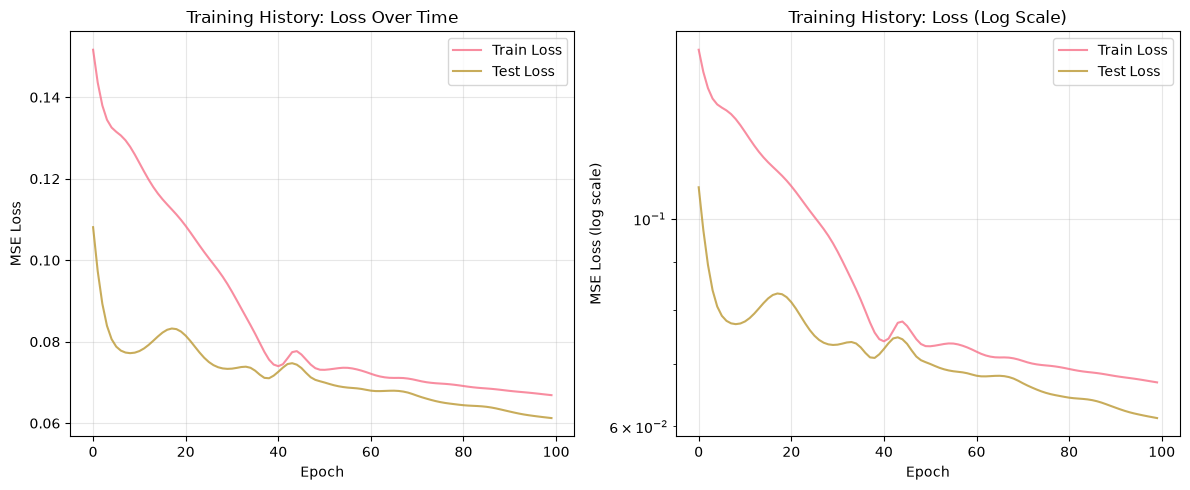


Training Complete!
  - Final train loss: 0.066876
  - Final test loss: 0.061249


In [6]:
# Training function
def train_model(model, X_train, y_train, X_test, y_test, num_epochs=100, learning_rate=0.001):
    """
    Train the RNN model and track performance
    """
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    train_losses = []
    test_losses = []
    
    model.train()
    for epoch in range(num_epochs):
        # Forward pass
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        
        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # Evaluate on test set
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
        model.train()
        
        train_losses.append(loss.item())
        test_losses.append(test_loss.item())
        
        if (epoch + 1) % 20 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {loss.item():.6f}, Test Loss: {test_loss.item():.6f}")
    
    return train_losses, test_losses

# Train the model
print("Training Simple RNN...\n")
train_losses, test_losses = train_model(
    model_rnn, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
    num_epochs=100, learning_rate=0.001
)

# Plot training history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', alpha=0.8)
plt.plot(test_losses, label='Test Loss', alpha=0.8)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training History: Loss Over Time')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(train_losses, label='Train Loss', alpha=0.8)
plt.plot(test_losses, label='Test Loss', alpha=0.8)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (log scale)')
plt.title('Training History: Loss (Log Scale)')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nTraining Complete!")
print(f"  - Final train loss: {train_losses[-1]:.6f}")
print(f"  - Final test loss: {test_losses[-1]:.6f}")

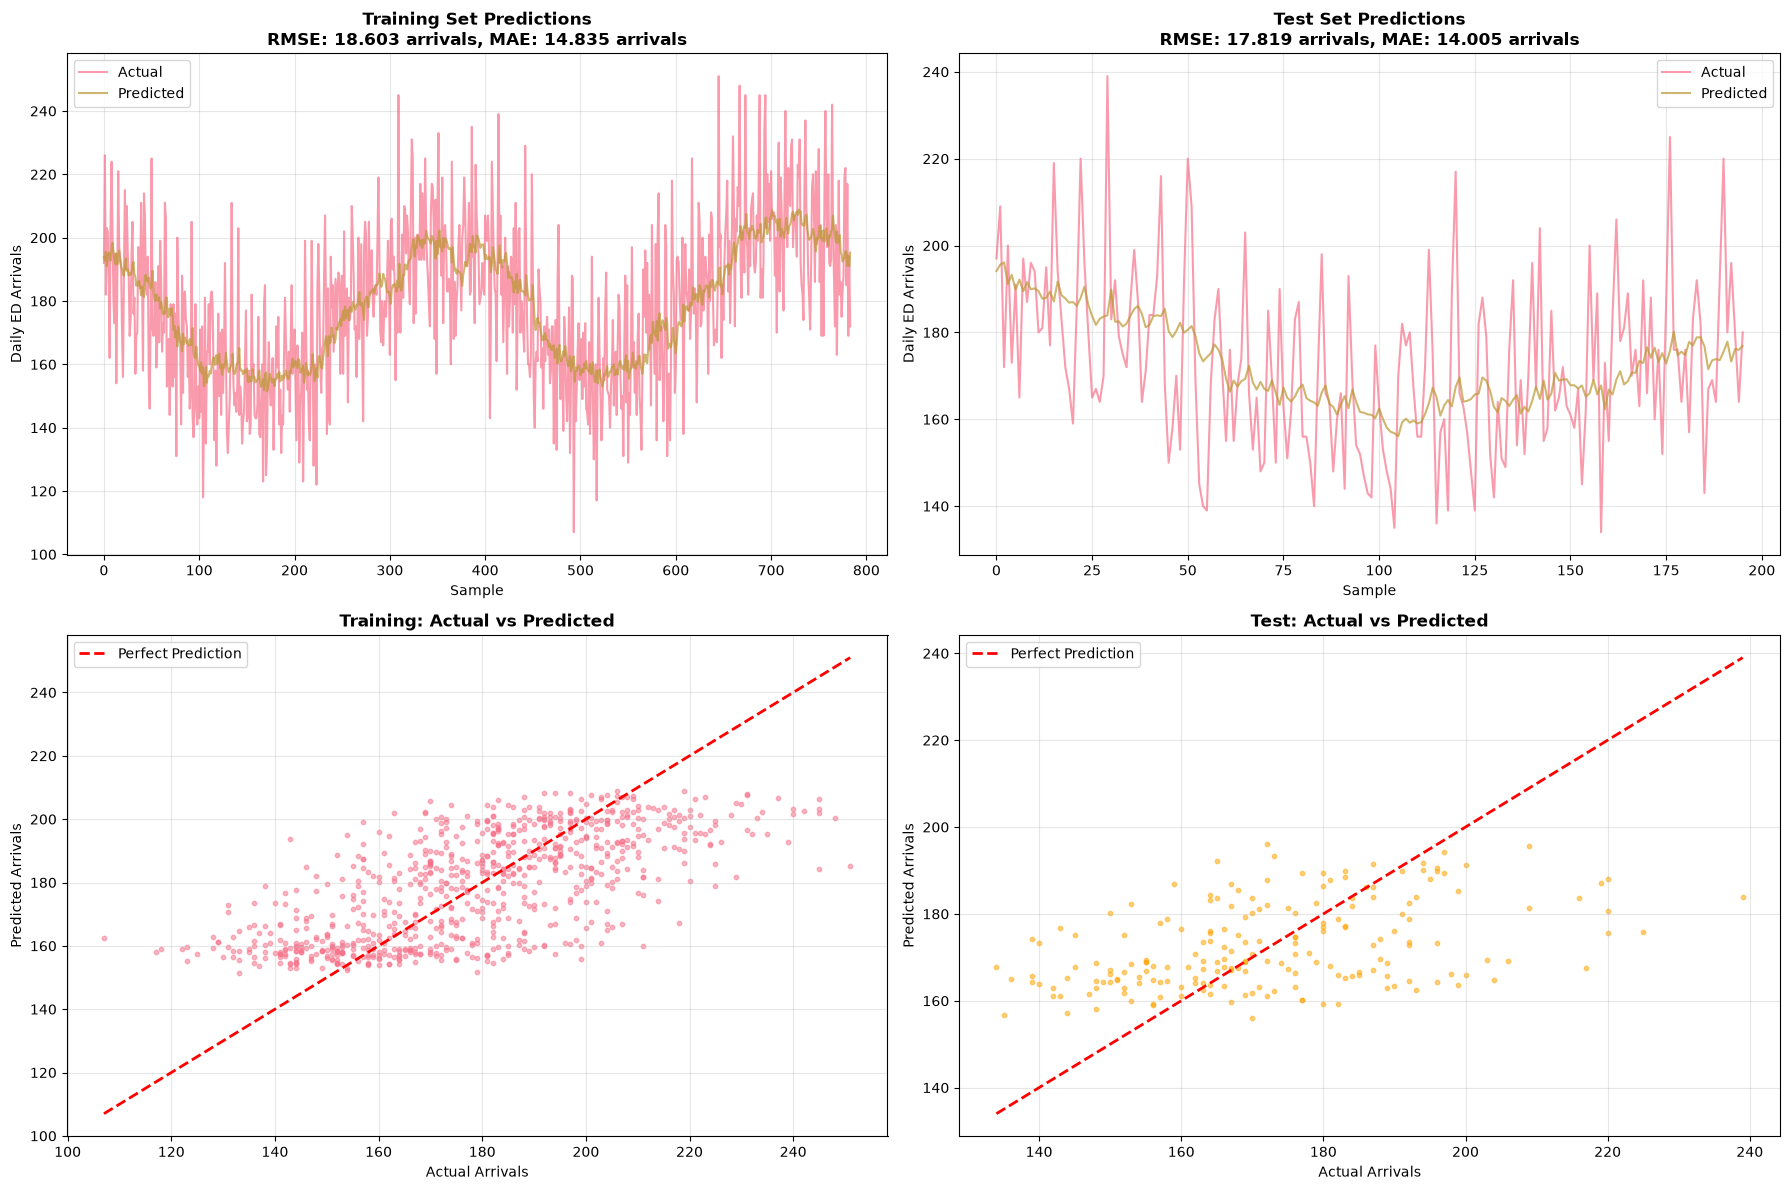


Simple RNN Performance:
  Training RMSE: 18.603 arrivals
  Test RMSE: 17.819 arrivals
  Training MAE: 14.835 arrivals
  Test MAE: 14.005 arrivals


In [7]:
# Make predictions and visualize results
model_rnn.eval()
with torch.no_grad():
    train_predictions = model_rnn(X_train_tensor).cpu().numpy()
    test_predictions = model_rnn(X_test_tensor).cpu().numpy()

# Denormalize predictions
train_predictions_denorm = scaler.inverse_transform(train_predictions)
test_predictions_denorm = scaler.inverse_transform(test_predictions)
y_train_denorm = scaler.inverse_transform(y_train.reshape(-1, 1))
y_test_denorm = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate metrics
train_rmse = np.sqrt(mean_squared_error(y_train_denorm, train_predictions_denorm))
test_rmse = np.sqrt(mean_squared_error(y_test_denorm, test_predictions_denorm))
train_mae = mean_absolute_error(y_train_denorm, train_predictions_denorm)
test_mae = mean_absolute_error(y_test_denorm, test_predictions_denorm)

# Visualize predictions
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Training predictions
axes[0, 0].plot(y_train_denorm, label='Actual', alpha=0.7, linewidth=1.5)
axes[0, 0].plot(train_predictions_denorm, label='Predicted', alpha=0.7, linewidth=1.5)
axes[0, 0].set_xlabel('Sample')
axes[0, 0].set_ylabel('Daily ED Arrivals')
axes[0, 0].set_title(f'Training Set Predictions\nRMSE: {train_rmse:.3f} arrivals, MAE: {train_mae:.3f} arrivals', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Test predictions
axes[0, 1].plot(y_test_denorm, label='Actual', alpha=0.7, linewidth=1.5)
axes[0, 1].plot(test_predictions_denorm, label='Predicted', alpha=0.7, linewidth=1.5)
axes[0, 1].set_xlabel('Sample')
axes[0, 1].set_ylabel('Daily ED Arrivals')
axes[0, 1].set_title(f'Test Set Predictions\nRMSE: {test_rmse:.3f} arrivals, MAE: {test_mae:.3f} arrivals', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Scatter plot: actual vs predicted (train)
axes[1, 0].scatter(y_train_denorm, train_predictions_denorm, alpha=0.5, s=10)
min_val = min(y_train_denorm.min(), train_predictions_denorm.min())
max_val = max(y_train_denorm.max(), train_predictions_denorm.max())
axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 0].set_xlabel('Actual Arrivals')
axes[1, 0].set_ylabel('Predicted Arrivals')
axes[1, 0].set_title('Training: Actual vs Predicted', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Scatter plot: actual vs predicted (test)
axes[1, 1].scatter(y_test_denorm, test_predictions_denorm, alpha=0.5, s=10, c='orange')
min_val = min(y_test_denorm.min(), test_predictions_denorm.min())
max_val = max(y_test_denorm.max(), test_predictions_denorm.max())
axes[1, 1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 1].set_xlabel('Actual Arrivals')
axes[1, 1].set_ylabel('Predicted Arrivals')
axes[1, 1].set_title('Test: Actual vs Predicted', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSimple RNN Performance:")
print(f"  Training RMSE: {train_rmse:.3f} arrivals")
print(f"  Test RMSE: {test_rmse:.3f} arrivals")
print(f"  Training MAE: {train_mae:.3f} arrivals")
print(f"  Test MAE: {test_mae:.3f} arrivals")

### The Vanishing Gradient Problem

Simple RNNs have a critical weakness: **vanishing gradients**.

**What Happens:**
- During backpropagation through time, gradients get multiplied many times
- If gradients are < 1, they shrink exponentially: 0.9^20 = 0.12
- Network can't learn long-term dependencies

**Example:**
```
"The patient was admitted in January and was discharged in [month]"
```
Simple RNN struggles to connect "January" with "July" (distant relationship)

**Solution:** LSTM and GRU architectures (next sections)

---
## 4. LSTM - Long Short-Term Memory Networks

LSTM networks solve the vanishing gradient problem by introducing a **cell state** and **gates** that control information flow.

### LSTM Architecture

LSTM has four components:

1. **Cell State (C_t)**: The "memory highway" - information flows with minimal modification
2. **Forget Gate (f_t)**: Decides what to remove from cell state
3. **Input Gate (i_t)**: Decides what new information to add
4. **Output Gate (o_t)**: Decides what to output based on cell state

**Mathematical Formulas:**

```
Forget Gate:    f_t = σ(W_f · [h_t-1, x_t] + b_f)
Input Gate:     i_t = σ(W_i · [h_t-1, x_t] + b_i)
Candidate:      C̃_t = tanh(W_C · [h_t-1, x_t] + b_C)
Cell State:     C_t = f_t * C_t-1 + i_t * C̃_t
Output Gate:    o_t = σ(W_o · [h_t-1, x_t] + b_o)
Hidden State:   h_t = o_t * tanh(C_t)
```

Where:
- σ = sigmoid function (outputs between 0 and 1)
- * = element-wise multiplication
- Gates output values 0-1 (0 = block all, 1 = let all through)

In [8]:
# Define LSTM model
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1, output_size=1):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Fully connected layer
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        # Initialize hidden state and cell state
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        # Forward propagate LSTM
        out, (hn, cn) = self.lstm(x, (h0, c0))
        
        # Decode the last time step
        out = self.fc(out[:, -1, :])
        
        return out

# Create and train LSTM model
model_lstm = LSTMModel(input_size=1, hidden_size=32, num_layers=1, output_size=1)
model_lstm = model_lstm.to(device)

print("🏗️ LSTM Architecture:")
print(model_lstm)
print(f"\n📊 Model Parameters:")
total_params = sum(p.numel() for p in model_lstm.parameters())
print(f"  • Total parameters: {total_params:,}")
print(f"  • Note: LSTM has 4x more parameters than simple RNN (gates!)")

🏗️ LSTM Architecture:
LSTMModel(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)

📊 Model Parameters:
  • Total parameters: 4,513
  • Note: LSTM has 4x more parameters than simple RNN (gates!)


In [9]:
# Train LSTM
print("🚀 Training LSTM...\n")
train_losses_lstm, test_losses_lstm = train_model(
    model_lstm, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
    num_epochs=100, learning_rate=0.001
)

# Make predictions
model_lstm.eval()
with torch.no_grad():
    train_predictions_lstm = model_lstm(X_train_tensor).cpu().numpy()
    test_predictions_lstm = model_lstm(X_test_tensor).cpu().numpy()

# Denormalize
train_predictions_lstm_denorm = scaler.inverse_transform(train_predictions_lstm)
test_predictions_lstm_denorm = scaler.inverse_transform(test_predictions_lstm)

# Calculate metrics
train_rmse_lstm = np.sqrt(mean_squared_error(y_train_denorm, train_predictions_lstm_denorm))
test_rmse_lstm = np.sqrt(mean_squared_error(y_test_denorm, test_predictions_lstm_denorm))
train_mae_lstm = mean_absolute_error(y_train_denorm, train_predictions_lstm_denorm)
test_mae_lstm = mean_absolute_error(y_test_denorm, test_predictions_lstm_denorm)

print(f"\n📊 LSTM Performance:")
print(f"  Training RMSE: {train_rmse_lstm:.3f} arrivals")
print(f"  Test RMSE: {test_rmse_lstm:.3f} arrivals")
print(f"  Training MAE: {train_mae_lstm:.3f} arrivals")
print(f"  Test MAE: {test_mae_lstm:.3f} arrivals")

print(f"\n📈 Improvement over Simple RNN:")
print(f"  Test RMSE reduction: {((test_rmse - test_rmse_lstm) / test_rmse * 100):.1f}%")
print(f"  Test MAE reduction: {((test_mae - test_mae_lstm) / test_mae * 100):.1f}%")

🚀 Training LSTM...



Epoch [20/100], Train Loss: 0.116245, Test Loss: 0.077303


Epoch [40/100], Train Loss: 0.101344, Test Loss: 0.074973


Epoch [60/100], Train Loss: 0.075692, Test Loss: 0.074307


Epoch [80/100], Train Loss: 0.070788, Test Loss: 0.068039


Epoch [100/100], Train Loss: 0.070538, Test Loss: 0.067267

📊 LSTM Performance:
  Training RMSE: 19.118 arrivals
  Test RMSE: 18.674 arrivals
  Training MAE: 15.253 arrivals
  Test MAE: 14.844 arrivals

📈 Improvement over Simple RNN:
  Test RMSE reduction: -4.8%
  Test MAE reduction: -6.0%


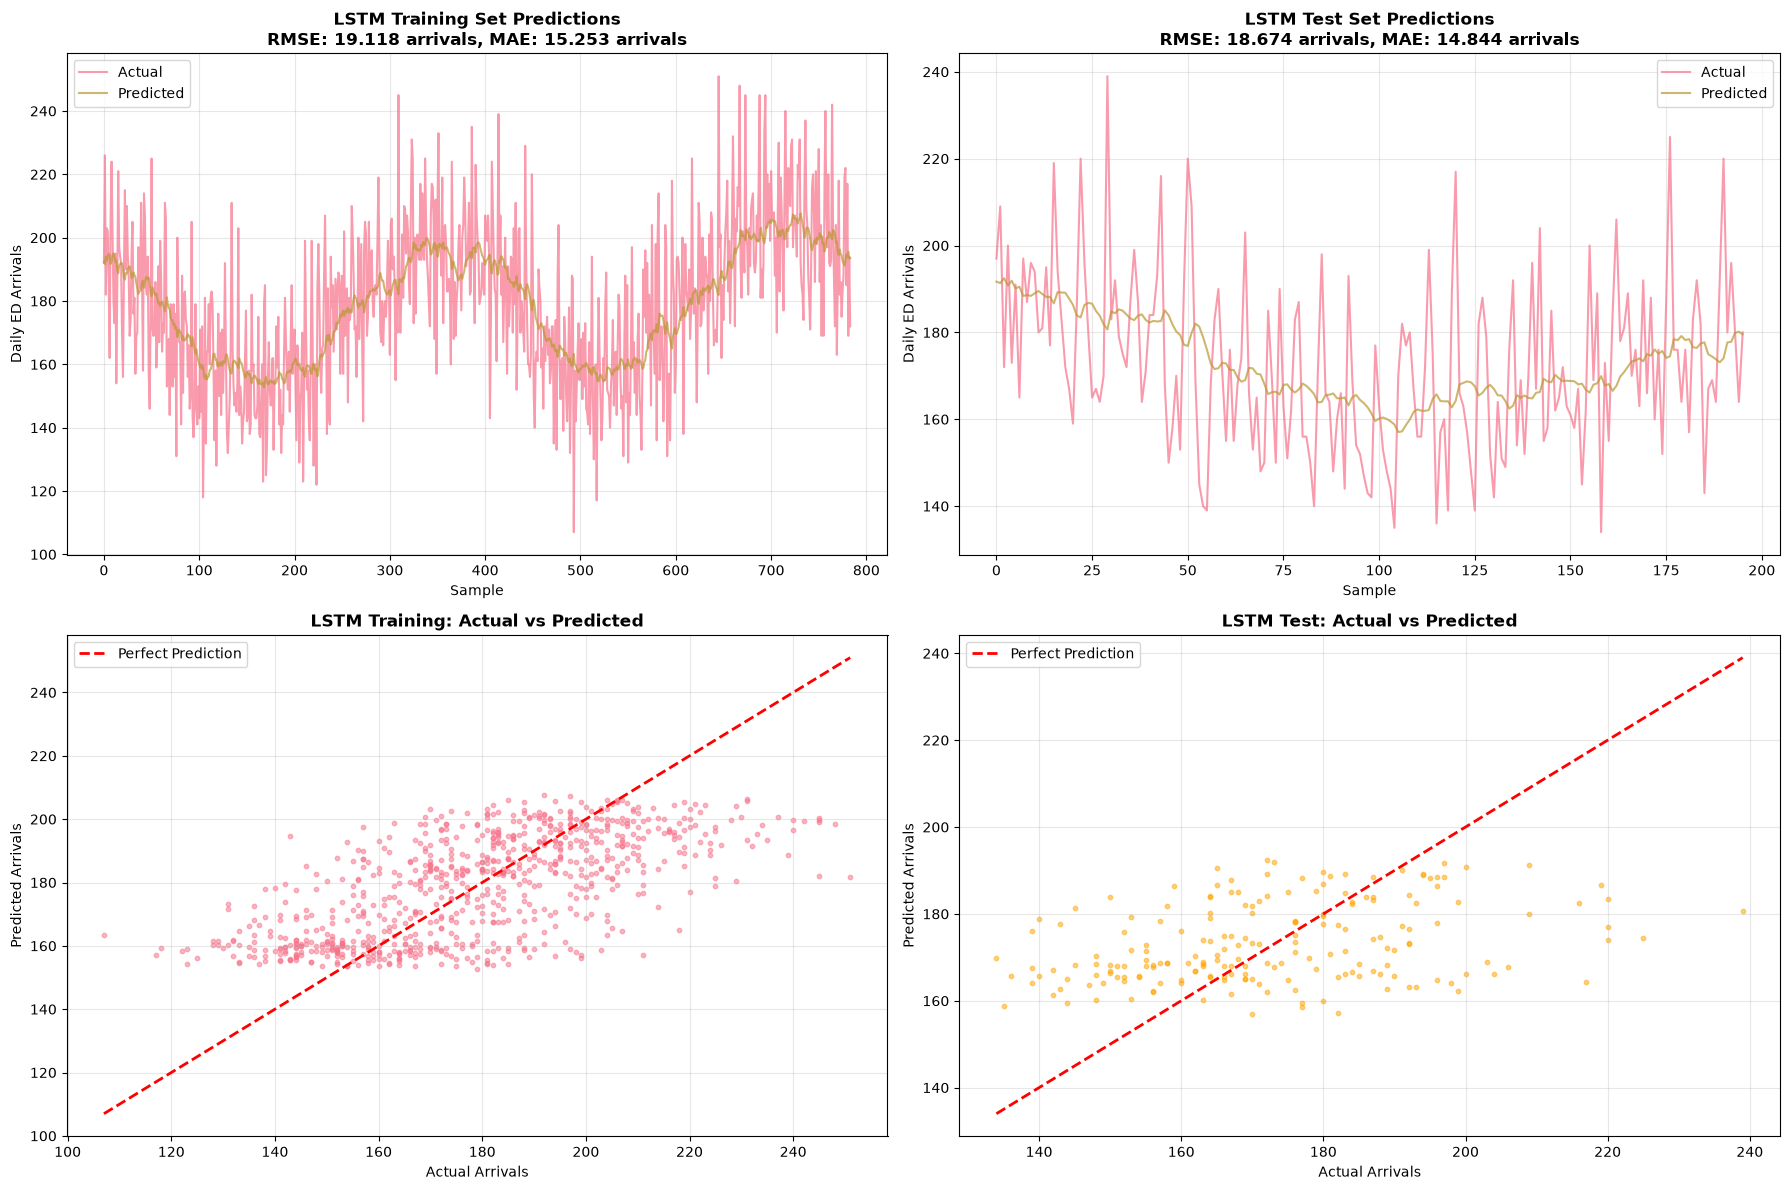

In [10]:
# Visualize LSTM predictions
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Training predictions
axes[0, 0].plot(y_train_denorm, label='Actual', alpha=0.7, linewidth=1.5)
axes[0, 0].plot(train_predictions_lstm_denorm, label='Predicted', alpha=0.7, linewidth=1.5)
axes[0, 0].set_xlabel('Sample')
axes[0, 0].set_ylabel('Daily ED Arrivals')
axes[0, 0].set_title(f'LSTM Training Set Predictions\nRMSE: {train_rmse_lstm:.3f} arrivals, MAE: {train_mae_lstm:.3f} arrivals', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Test predictions
axes[0, 1].plot(y_test_denorm, label='Actual', alpha=0.7, linewidth=1.5)
axes[0, 1].plot(test_predictions_lstm_denorm, label='Predicted', alpha=0.7, linewidth=1.5)
axes[0, 1].set_xlabel('Sample')
axes[0, 1].set_ylabel('Daily ED Arrivals')
axes[0, 1].set_title(f'LSTM Test Set Predictions\nRMSE: {test_rmse_lstm:.3f} arrivals, MAE: {test_mae_lstm:.3f} arrivals', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Scatter plot: actual vs predicted (train)
axes[1, 0].scatter(y_train_denorm, train_predictions_lstm_denorm, alpha=0.5, s=10)
min_val = min(y_train_denorm.min(), train_predictions_lstm_denorm.min())
max_val = max(y_train_denorm.max(), train_predictions_lstm_denorm.max())
axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 0].set_xlabel('Actual Arrivals')
axes[1, 0].set_ylabel('Predicted Arrivals')
axes[1, 0].set_title('LSTM Training: Actual vs Predicted', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Scatter plot: actual vs predicted (test)
axes[1, 1].scatter(y_test_denorm, test_predictions_lstm_denorm, alpha=0.5, s=10, c='orange')
min_val = min(y_test_denorm.min(), test_predictions_lstm_denorm.min())
max_val = max(y_test_denorm.max(), test_predictions_lstm_denorm.max())
axes[1, 1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 1].set_xlabel('Actual Arrivals')
axes[1, 1].set_ylabel('Predicted Arrivals')
axes[1, 1].set_title('LSTM Test: Actual vs Predicted', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 5. GRU - Gated Recurrent Unit

GRU is a simplified version of LSTM with fewer parameters, often achieving similar performance.

### GRU Architecture

GRU simplifies LSTM by:
- Merging cell state and hidden state
- Using only 2 gates instead of 3

**Components:**
1. **Reset Gate (r_t)**: Decides how much past information to forget
2. **Update Gate (z_t)**: Decides how much to update with new information

**Mathematical Formulas:**

```
Reset Gate:     r_t = σ(W_r · [h_t-1, x_t])
Update Gate:    z_t = σ(W_z · [h_t-1, x_t])
Candidate:      h̃_t = tanh(W · [r_t * h_t-1, x_t])
Hidden State:   h_t = (1 - z_t) * h_t-1 + z_t * h̃_t
```

**Advantages:**
- ✅ Fewer parameters than LSTM → faster training
- ✅ Often similar performance to LSTM
- ✅ Better on smaller datasets (less prone to overfitting)

**When to use:**
- Limited training data
- Need faster training/inference
- LSTM is overfitting

In [11]:
# Define GRU model
class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1, output_size=1):
        super(GRUModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # GRU layer
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Fully connected layer
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        # Initialize hidden state
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        # Forward propagate GRU
        out, hn = self.gru(x, h0)
        
        # Decode the last time step
        out = self.fc(out[:, -1, :])
        
        return out

# Create and train GRU model
model_gru = GRUModel(input_size=1, hidden_size=32, num_layers=1, output_size=1)
model_gru = model_gru.to(device)

print("🏗️ GRU Architecture:")
print(model_gru)
print(f"\n📊 Parameter Comparison:")
rnn_params = sum(p.numel() for p in model_rnn.parameters())
lstm_params = sum(p.numel() for p in model_lstm.parameters())
gru_params = sum(p.numel() for p in model_gru.parameters())
print(f"  • Simple RNN: {rnn_params:,} parameters")
print(f"  • LSTM: {lstm_params:,} parameters")
print(f"  • GRU: {gru_params:,} parameters")
print(f"  • GRU has {((lstm_params - gru_params) / lstm_params * 100):.1f}% fewer parameters than LSTM")

🏗️ GRU Architecture:
GRUModel(
  (gru): GRU(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)

📊 Parameter Comparison:
  • Simple RNN: 1,153 parameters
  • LSTM: 4,513 parameters
  • GRU: 3,393 parameters
  • GRU has 24.8% fewer parameters than LSTM


In [12]:
# Train GRU
print("🚀 Training GRU...\n")
train_losses_gru, test_losses_gru = train_model(
    model_gru, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
    num_epochs=100, learning_rate=0.001
)

# Make predictions
model_gru.eval()
with torch.no_grad():
    train_predictions_gru = model_gru(X_train_tensor).cpu().numpy()
    test_predictions_gru = model_gru(X_test_tensor).cpu().numpy()

# Denormalize
train_predictions_gru_denorm = scaler.inverse_transform(train_predictions_gru)
test_predictions_gru_denorm = scaler.inverse_transform(test_predictions_gru)

# Calculate metrics
train_rmse_gru = np.sqrt(mean_squared_error(y_train_denorm, train_predictions_gru_denorm))
test_rmse_gru = np.sqrt(mean_squared_error(y_test_denorm, test_predictions_gru_denorm))
train_mae_gru = mean_absolute_error(y_train_denorm, train_predictions_gru_denorm)
test_mae_gru = mean_absolute_error(y_test_denorm, test_predictions_gru_denorm)

print(f"\n📊 GRU Performance:")
print(f"  Training RMSE: {train_rmse_gru:.3f} arrivals")
print(f"  Test RMSE: {test_rmse_gru:.3f} arrivals")
print(f"  Training MAE: {train_mae_gru:.3f} arrivals")
print(f"  Test MAE: {test_mae_gru:.3f} arrivals")

🚀 Training GRU...



Epoch [20/100], Train Loss: 0.111697, Test Loss: 0.078302


Epoch [40/100], Train Loss: 0.088004, Test Loss: 0.071523


Epoch [60/100], Train Loss: 0.071904, Test Loss: 0.068388


Epoch [80/100], Train Loss: 0.070821, Test Loss: 0.067527


Epoch [100/100], Train Loss: 0.070589, Test Loss: 0.066980

📊 GRU Performance:
  Training RMSE: 19.128 arrivals
  Test RMSE: 18.634 arrivals
  Training MAE: 15.273 arrivals
  Test MAE: 14.838 arrivals


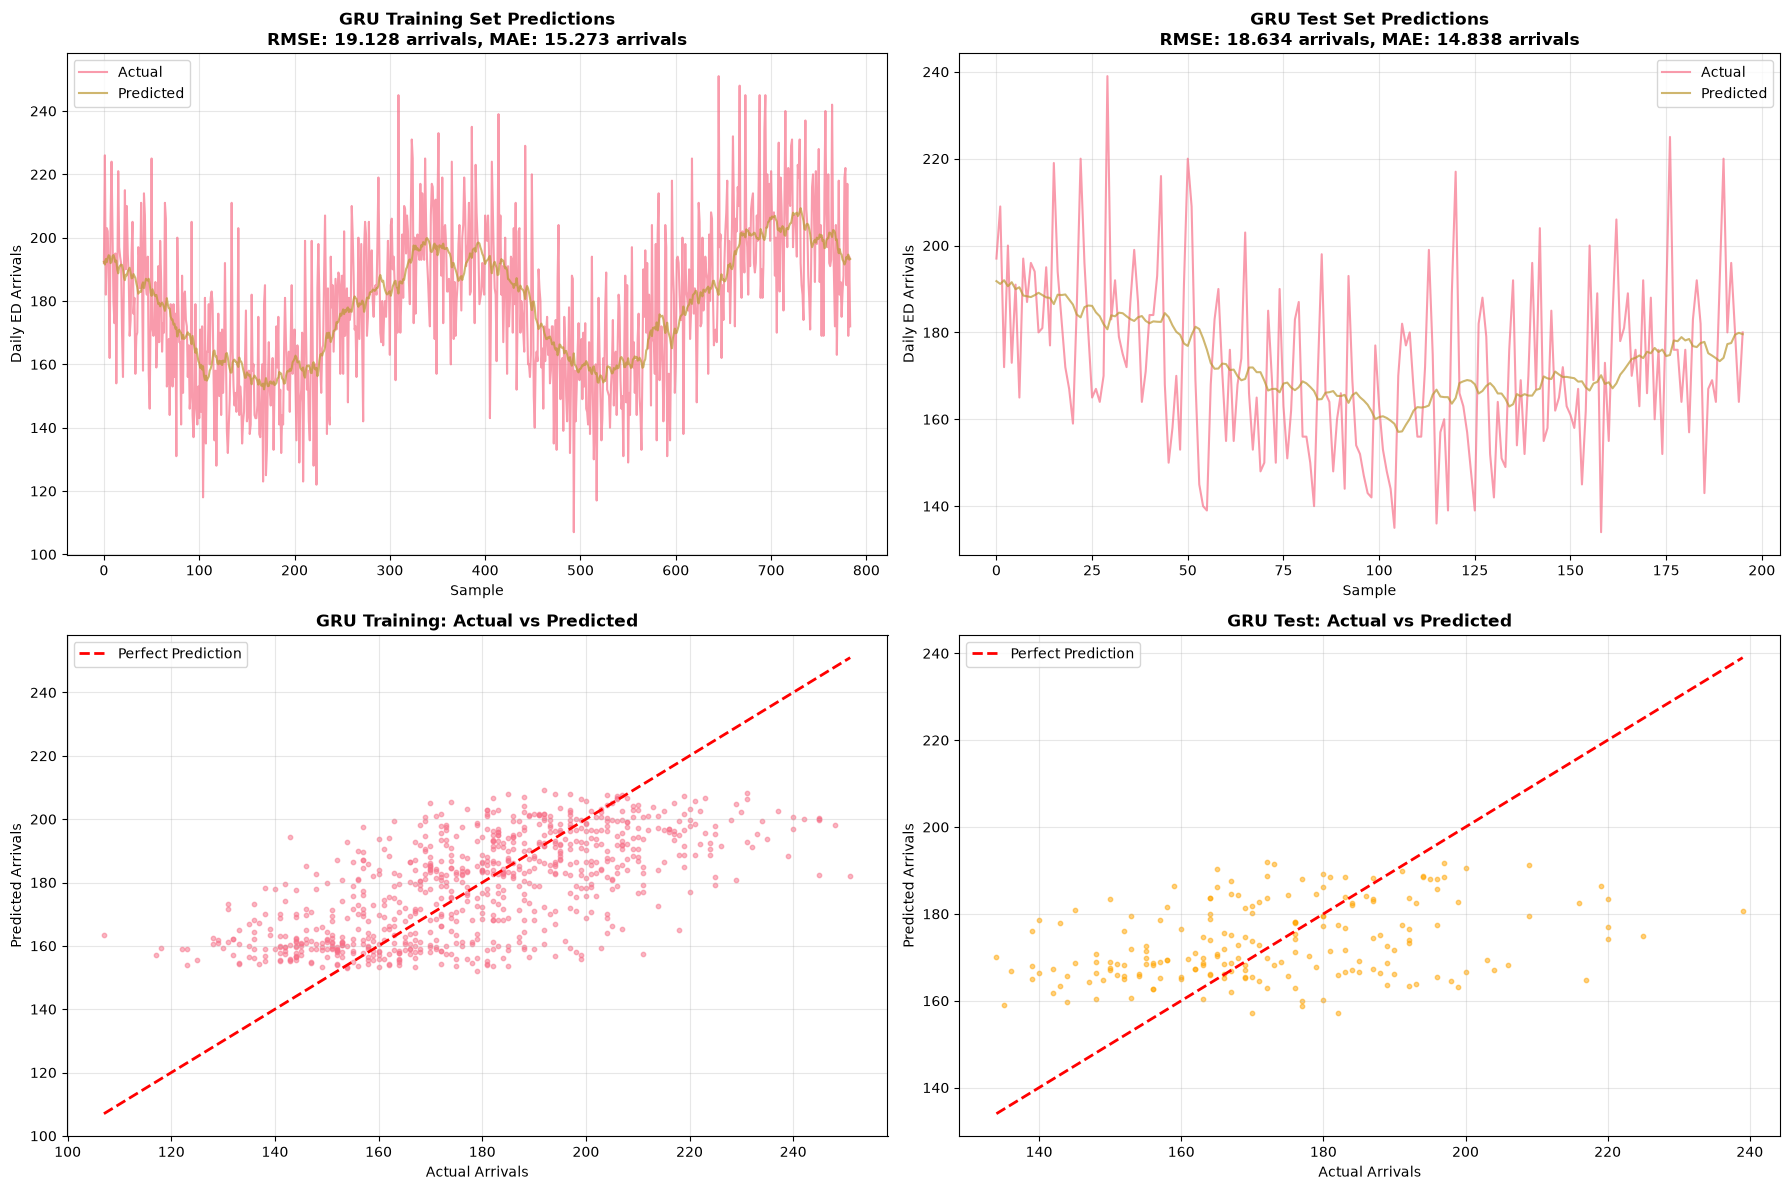

In [13]:
# Visualize GRU predictions
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Training predictions
axes[0, 0].plot(y_train_denorm, label='Actual', alpha=0.7, linewidth=1.5)
axes[0, 0].plot(train_predictions_gru_denorm, label='Predicted', alpha=0.7, linewidth=1.5)
axes[0, 0].set_xlabel('Sample')
axes[0, 0].set_ylabel('Daily ED Arrivals')
axes[0, 0].set_title(f'GRU Training Set Predictions\nRMSE: {train_rmse_gru:.3f} arrivals, MAE: {train_mae_gru:.3f} arrivals', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Test predictions
axes[0, 1].plot(y_test_denorm, label='Actual', alpha=0.7, linewidth=1.5)
axes[0, 1].plot(test_predictions_gru_denorm, label='Predicted', alpha=0.7, linewidth=1.5)
axes[0, 1].set_xlabel('Sample')
axes[0, 1].set_ylabel('Daily ED Arrivals')
axes[0, 1].set_title(f'GRU Test Set Predictions\nRMSE: {test_rmse_gru:.3f} arrivals, MAE: {test_mae_gru:.3f} arrivals', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Scatter plot: actual vs predicted (train)
axes[1, 0].scatter(y_train_denorm, train_predictions_gru_denorm, alpha=0.5, s=10)
min_val = min(y_train_denorm.min(), train_predictions_gru_denorm.min())
max_val = max(y_train_denorm.max(), train_predictions_gru_denorm.max())
axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 0].set_xlabel('Actual Arrivals')
axes[1, 0].set_ylabel('Predicted Arrivals')
axes[1, 0].set_title('GRU Training: Actual vs Predicted', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Scatter plot: actual vs predicted (test)
axes[1, 1].scatter(y_test_denorm, test_predictions_gru_denorm, alpha=0.5, s=10, c='orange')
min_val = min(y_test_denorm.min(), test_predictions_gru_denorm.min())
max_val = max(y_test_denorm.max(), test_predictions_gru_denorm.max())
axes[1, 1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 1].set_xlabel('Actual Arrivals')
axes[1, 1].set_ylabel('Predicted Arrivals')
axes[1, 1].set_title('GRU Test: Actual vs Predicted', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. Comprehensive Model Comparison

Let's compare all three architectures side-by-side.

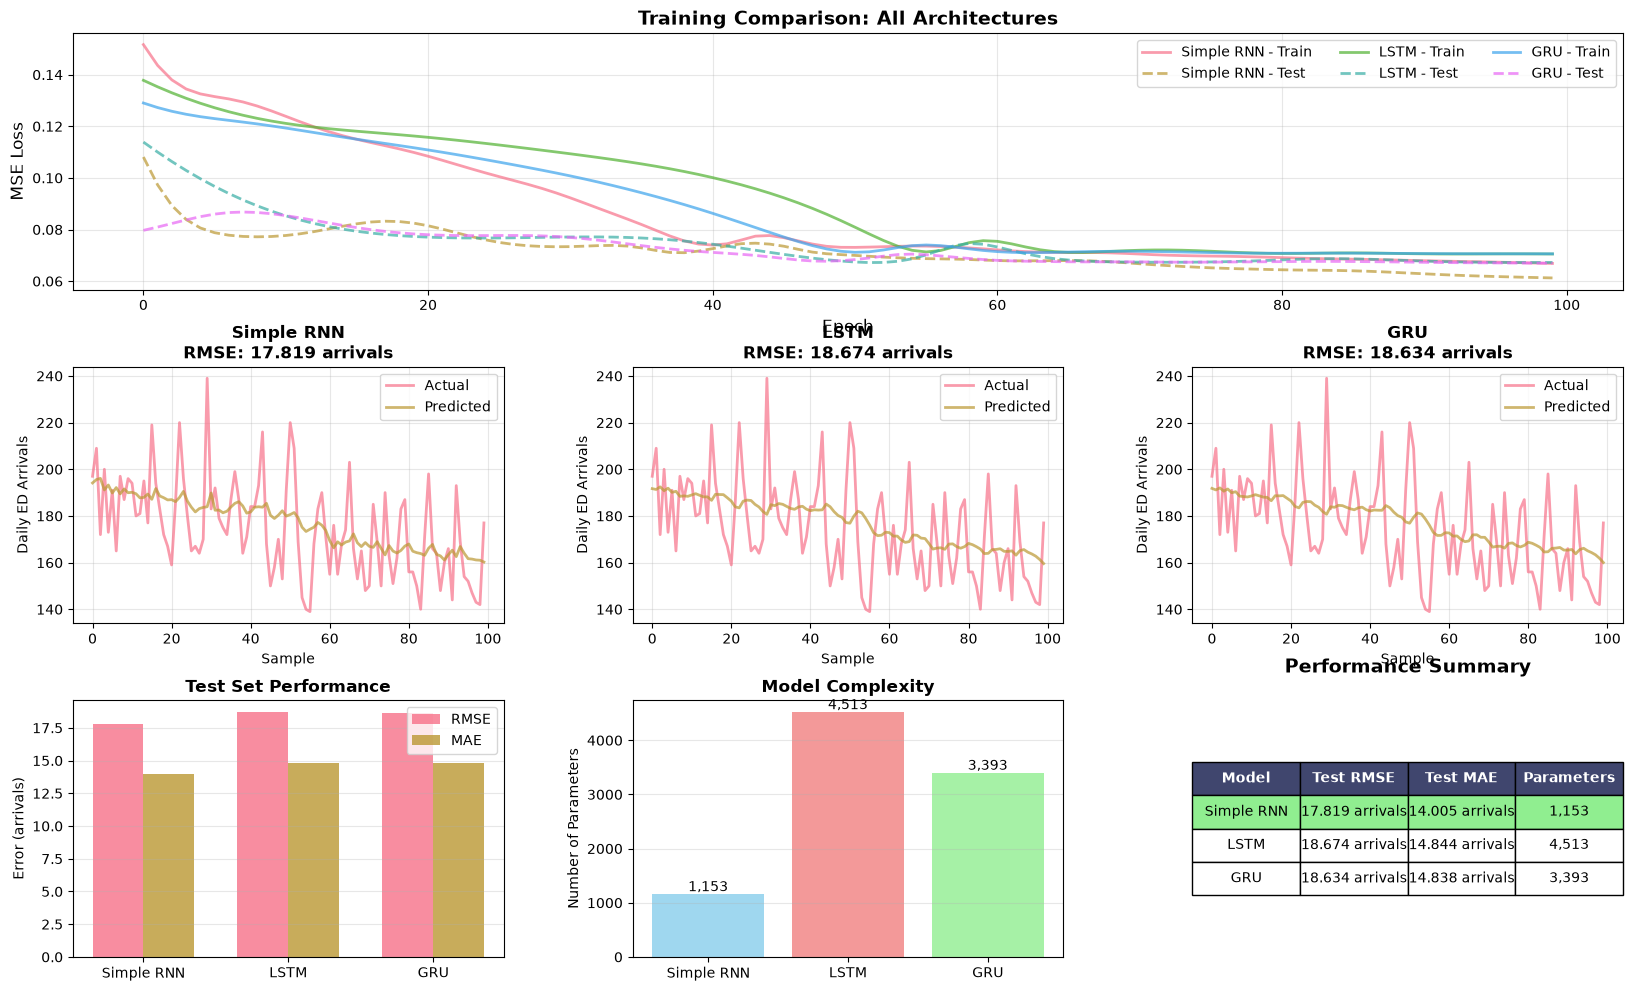


COMPREHENSIVE MODEL COMPARISON

Simple RNN:
  - Test RMSE: 17.8190 arrivals
  - Test MAE: 14.0046 arrivals
  - Parameters: 1,153
  - Final train loss: 0.066876
  - Final test loss: 0.061249

LSTM:
  - Test RMSE: 18.6739 arrivals
  - Test MAE: 14.8444 arrivals
  - Parameters: 4,513
  - Final train loss: 0.070538
  - Final test loss: 0.067267

GRU:
  - Test RMSE: 18.6340 arrivals
  - Test MAE: 14.8382 arrivals
  - Parameters: 3,393
  - Final train loss: 0.070589
  - Final test loss: 0.066980

WINNER: Simple RNN


In [14]:
# Comprehensive comparison visualization
fig = plt.figure(figsize=(20, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Training loss comparison
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(train_losses, label='Simple RNN - Train', alpha=0.7, linewidth=2)
ax1.plot(test_losses, label='Simple RNN - Test', alpha=0.7, linewidth=2, linestyle='--')
ax1.plot(train_losses_lstm, label='LSTM - Train', alpha=0.7, linewidth=2)
ax1.plot(test_losses_lstm, label='LSTM - Test', alpha=0.7, linewidth=2, linestyle='--')
ax1.plot(train_losses_gru, label='GRU - Train', alpha=0.7, linewidth=2)
ax1.plot(test_losses_gru, label='GRU - Test', alpha=0.7, linewidth=2, linestyle='--')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('MSE Loss', fontsize=12)
ax1.set_title('Training Comparison: All Architectures', fontsize=14, fontweight='bold')
ax1.legend(ncol=3)
ax1.grid(True, alpha=0.3)

# 2. Test predictions - RNN
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(y_test_denorm[:100], label='Actual', alpha=0.7, linewidth=2)
ax2.plot(test_predictions_denorm[:100], label='Predicted', alpha=0.7, linewidth=2)
ax2.set_xlabel('Sample')
ax2.set_ylabel('Daily ED Arrivals')
ax2.set_title(f'Simple RNN\nRMSE: {test_rmse:.3f} arrivals', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Test predictions - LSTM
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(y_test_denorm[:100], label='Actual', alpha=0.7, linewidth=2)
ax3.plot(test_predictions_lstm_denorm[:100], label='Predicted', alpha=0.7, linewidth=2)
ax3.set_xlabel('Sample')
ax3.set_ylabel('Daily ED Arrivals')
ax3.set_title(f'LSTM\nRMSE: {test_rmse_lstm:.3f} arrivals', fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Test predictions - GRU
ax4 = fig.add_subplot(gs[1, 2])
ax4.plot(y_test_denorm[:100], label='Actual', alpha=0.7, linewidth=2)
ax4.plot(test_predictions_gru_denorm[:100], label='Predicted', alpha=0.7, linewidth=2)
ax4.set_xlabel('Sample')
ax4.set_ylabel('Daily ED Arrivals')
ax4.set_title(f'GRU\nRMSE: {test_rmse_gru:.3f} arrivals', fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Performance metrics comparison
ax5 = fig.add_subplot(gs[2, 0])
models = ['Simple RNN', 'LSTM', 'GRU']
test_rmses = [test_rmse, test_rmse_lstm, test_rmse_gru]
test_maes = [test_mae, test_mae_lstm, test_mae_gru]

x = np.arange(len(models))
width = 0.35
ax5.bar(x - width/2, test_rmses, width, label='RMSE', alpha=0.8)
ax5.bar(x + width/2, test_maes, width, label='MAE', alpha=0.8)
ax5.set_ylabel('Error (arrivals)')
ax5.set_title('Test Set Performance', fontweight='bold')
ax5.set_xticks(x)
ax5.set_xticklabels(models)
ax5.legend()
ax5.grid(True, alpha=0.3, axis='y')

# 6. Parameter count comparison
ax6 = fig.add_subplot(gs[2, 1])
param_counts = [rnn_params, lstm_params, gru_params]
colors = ['skyblue', 'lightcoral', 'lightgreen']
bars = ax6.bar(models, param_counts, color=colors, alpha=0.8)
ax6.set_ylabel('Number of Parameters')
ax6.set_title('Model Complexity', fontweight='bold')
ax6.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height):,}',
            ha='center', va='bottom')

# 7. Summary table
ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')

summary_data = [
    ['Model', 'Test RMSE', 'Test MAE', 'Parameters'],
    ['Simple RNN', f'{test_rmse:.3f} arrivals', f'{test_mae:.3f} arrivals', f'{rnn_params:,}'],
    ['LSTM', f'{test_rmse_lstm:.3f} arrivals', f'{test_mae_lstm:.3f} arrivals', f'{lstm_params:,}'],
    ['GRU', f'{test_rmse_gru:.3f} arrivals', f'{test_mae_gru:.3f} arrivals', f'{gru_params:,}']
]

table = ax7.table(cellText=summary_data, cellLoc='center', loc='center',
                  colWidths=[0.25, 0.25, 0.25, 0.25])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Style header row
for i in range(4):
    table[(0, i)].set_facecolor('#40466e')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Highlight best performance
best_idx = np.argmin(test_rmses) + 1
for i in range(4):
    table[(best_idx, i)].set_facecolor('#90ee90')

ax7.set_title('Performance Summary', fontsize=14, fontweight='bold', pad=20)

plt.show()

# Print detailed comparison
print("\n" + "="*70)
print("COMPREHENSIVE MODEL COMPARISON")
print("="*70)

for i, model_name in enumerate(['Simple RNN', 'LSTM', 'GRU']):
    rmse = [test_rmse, test_rmse_lstm, test_rmse_gru][i]
    mae = [test_mae, test_mae_lstm, test_mae_gru][i]
    params = [rnn_params, lstm_params, gru_params][i]
    
    print(f"\n{model_name}:")
    print(f"  - Test RMSE: {rmse:.4f} arrivals")
    print(f"  - Test MAE: {mae:.4f} arrivals")
    print(f"  - Parameters: {params:,}")
    print(f"  - Final train loss: {[train_losses[-1], train_losses_lstm[-1], train_losses_gru[-1]][i]:.6f}")
    print(f"  - Final test loss: {[test_losses[-1], test_losses_lstm[-1], test_losses_gru[-1]][i]:.6f}")

print("\n" + "="*70)
print("WINNER: " + models[np.argmin(test_rmses)])
print("="*70)

Phase Lag Analysis
Simple RNN: Lag = -1 steps, Correlation = 0.5434
LSTM:       Lag = -2 steps, Correlation = 0.4918
GRU:        Lag = -2 steps, Correlation = 0.4880

Note: Positive lag = predictions trail behind actuals
      Negative lag = predictions lead actuals


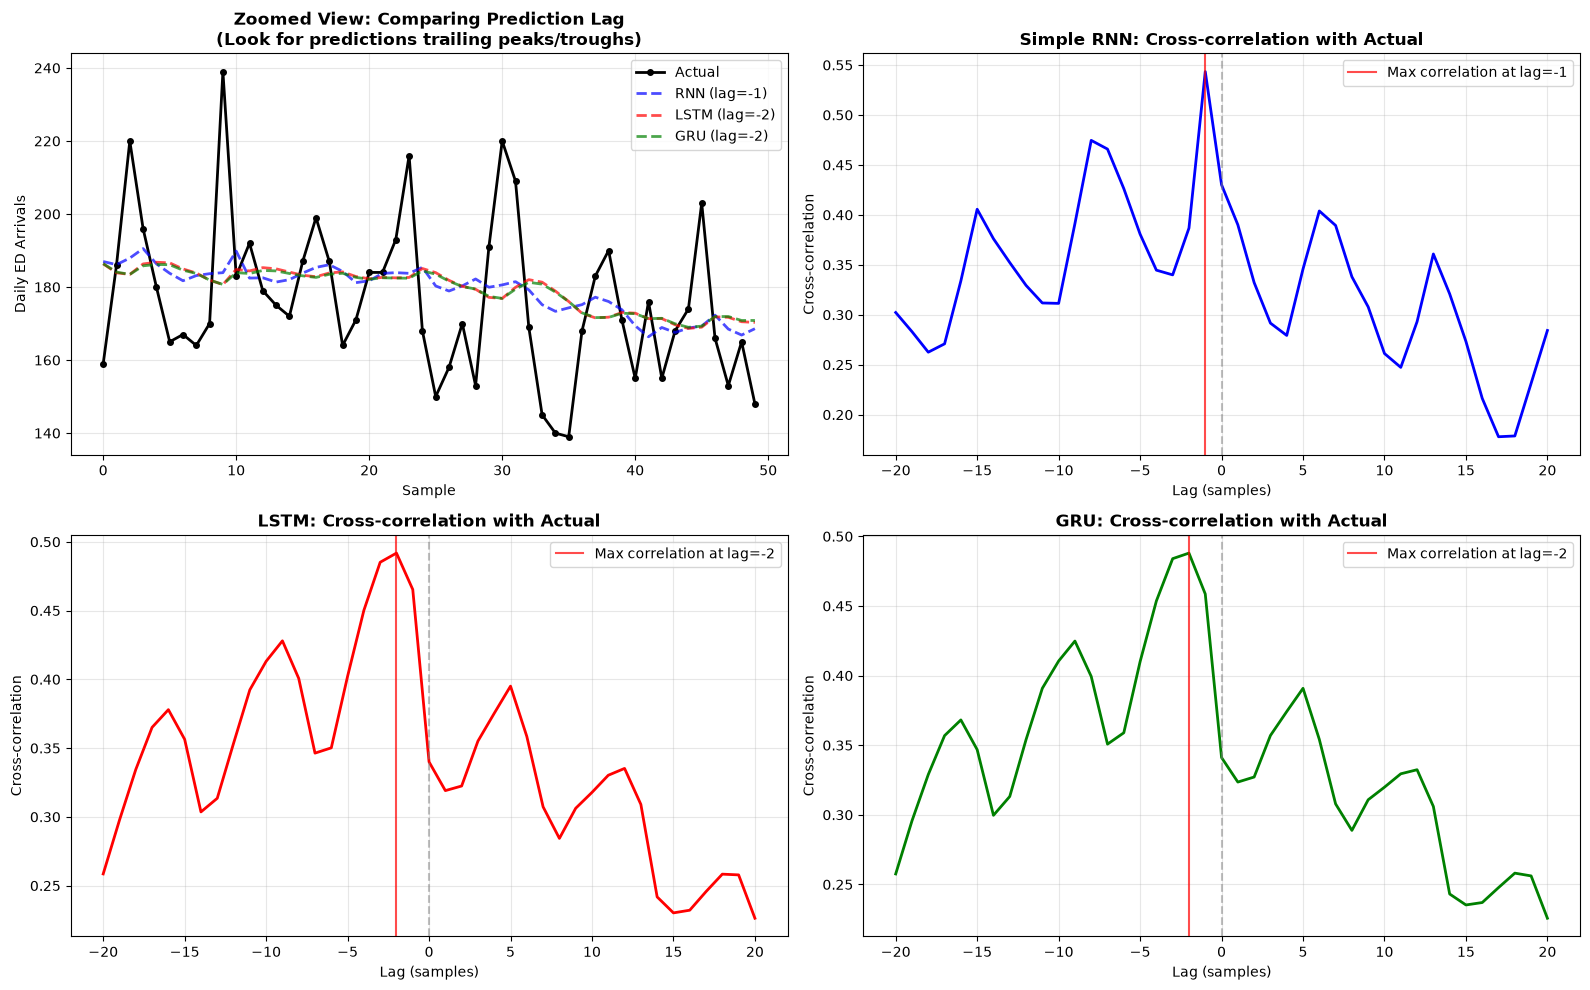


Interpretation:
--------------------------------------------------
LSTM shows less lag (-2 vs -1 steps) than Simple RNN.

Possible solutions for reducing lag:
  1. Use a different loss function (e.g., DTW-based loss)
  2. Add a penalty term for lagged predictions
  3. Increase model complexity or training epochs
  4. Use multi-step prediction targets instead of single-step


In [15]:
# Analyze phase lag (temporal shift) in predictions
from scipy import signal

def check_lag(actual, predicted, model_name):
    """
    Calculate cross-correlation to detect if predictions are lagging behind actuals.
    A positive lag means predictions are delayed relative to actual values.
    """
    actual_centered = actual.flatten() - actual.mean()
    predicted_centered = predicted.flatten() - predicted.mean()
    
    correlation = signal.correlate(actual_centered, predicted_centered, mode='full')
    lags = signal.correlation_lags(len(actual), len(predicted), mode='full')
    
    # Find the lag with maximum correlation
    optimal_lag = lags[np.argmax(correlation)]
    max_corr = np.max(correlation) / (np.std(actual) * np.std(predicted) * len(actual))
    
    return optimal_lag, max_corr

# Calculate lag for each model
lag_rnn, corr_rnn = check_lag(y_test_denorm, test_predictions_denorm, "Simple RNN")
lag_lstm, corr_lstm = check_lag(y_test_denorm, test_predictions_lstm_denorm, "LSTM")
lag_gru, corr_gru = check_lag(y_test_denorm, test_predictions_gru_denorm, "GRU")

print("Phase Lag Analysis")
print("=" * 50)
print(f"Simple RNN: Lag = {lag_rnn:+d} steps, Correlation = {corr_rnn:.4f}")
print(f"LSTM:       Lag = {lag_lstm:+d} steps, Correlation = {corr_lstm:.4f}")
print(f"GRU:        Lag = {lag_gru:+d} steps, Correlation = {corr_gru:.4f}")
print("\nNote: Positive lag = predictions trail behind actuals")
print("      Negative lag = predictions lead actuals")

# Visualize the lag effect
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Zoomed comparison showing lag
zoom_start, zoom_end = 20, 70

ax = axes[0, 0]
ax.plot(y_test_denorm[zoom_start:zoom_end], 'k-', linewidth=2, label='Actual', marker='o', markersize=4)
ax.plot(test_predictions_denorm[zoom_start:zoom_end], 'b--', linewidth=2, label=f'RNN (lag={lag_rnn})', alpha=0.7)
ax.plot(test_predictions_lstm_denorm[zoom_start:zoom_end], 'r--', linewidth=2, label=f'LSTM (lag={lag_lstm})', alpha=0.7)
ax.plot(test_predictions_gru_denorm[zoom_start:zoom_end], 'g--', linewidth=2, label=f'GRU (lag={lag_gru})', alpha=0.7)
ax.set_xlabel('Sample')
ax.set_ylabel('Daily ED Arrivals')
ax.set_title('Zoomed View: Comparing Prediction Lag\n(Look for predictions trailing peaks/troughs)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Cross-correlation plots
for idx, (model_name, predictions, color) in enumerate([
    ('Simple RNN', test_predictions_denorm, 'blue'),
    ('LSTM', test_predictions_lstm_denorm, 'red'),
    ('GRU', test_predictions_gru_denorm, 'green')
]):
    if idx < 3:
        ax = axes[0, 1] if idx == 0 else axes[1, idx-1]
        
        actual_centered = y_test_denorm.flatten() - y_test_denorm.mean()
        predicted_centered = predictions.flatten() - predictions.mean()
        
        correlation = signal.correlate(actual_centered, predicted_centered, mode='full')
        lags = signal.correlation_lags(len(y_test_denorm), len(predictions), mode='full')
        
        # Normalize correlation
        correlation = correlation / (np.std(y_test_denorm) * np.std(predictions) * len(y_test_denorm))
        
        # Plot only around lag 0
        mask = (lags >= -20) & (lags <= 20)
        ax.plot(lags[mask], correlation[mask], color=color, linewidth=2)
        ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
        ax.axvline(x=lags[np.argmax(correlation)], color='red', linestyle='-', alpha=0.7, 
                   label=f'Max correlation at lag={lags[np.argmax(correlation)]}')
        ax.set_xlabel('Lag (samples)')
        ax.set_ylabel('Cross-correlation')
        ax.set_title(f'{model_name}: Cross-correlation with Actual', fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Interpretation
print("\nInterpretation:")
print("-" * 50)
if lag_lstm > lag_rnn:
    print(f"LSTM shows more lag ({lag_lstm} vs {lag_rnn} steps) than Simple RNN.")
    print("This suggests LSTM may be relying more heavily on recent values,")
    print("essentially learning a 'persistence' forecast strategy.")
elif lag_lstm < lag_rnn:
    print(f"LSTM shows less lag ({lag_lstm} vs {lag_rnn} steps) than Simple RNN.")
else:
    print("Both models show similar lag behavior.")

print("\nPossible solutions for reducing lag:")
print("  1. Use a different loss function (e.g., DTW-based loss)")
print("  2. Add a penalty term for lagged predictions")
print("  3. Increase model complexity or training epochs")
print("  4. Use multi-step prediction targets instead of single-step")

### Key Takeaways from Comparison:

**Simple RNN:**
- ✅ Simplest architecture, easiest to understand
- ✅ Fewest parameters → fastest training
- ❌ Vanishing gradient problem
- ❌ Poor at learning long-term dependencies
- **Use when:** Very short sequences (<10 steps), educational purposes

**LSTM:**
- ✅ Excellent at long-term dependencies
- ✅ Most commonly used in production
- ✅ Well-researched and proven
- ❌ Most parameters → slower training
- ❌ More complex → harder to tune
- **Use when:** Long sequences, proven architecture needed, lots of data

**GRU:**
- ✅ Similar performance to LSTM with fewer parameters
- ✅ Faster training than LSTM
- ✅ Simpler than LSTM
- ✅ Often first choice for new projects
- ❌ Slightly less flexible than LSTM
- **Use when:** Limited data, need fast training, general-purpose sequence modeling

---
## 7. Interactive Parameter Exploration

Experiment with different hyperparameters to see how they affect model performance.

In [16]:
# Interactive RNN training widget
def interactive_rnn_training(model_type='LSTM', hidden_size=32, num_layers=1, 
                            learning_rate=0.001, num_epochs=50):
    """
    Interactively train different RNN architectures with different parameters
    """
    print(f"🚀 Training {model_type} with:")
    print(f"  • Hidden size: {hidden_size}")
    print(f"  • Num layers: {num_layers}")
    print(f"  • Learning rate: {learning_rate}")
    print(f"  • Epochs: {num_epochs}\n")
    
    # Create model based on type
    if model_type == 'Simple RNN':
        model = SimpleRNN(input_size=1, hidden_size=hidden_size, 
                         num_layers=num_layers, output_size=1)
    elif model_type == 'LSTM':
        model = LSTMModel(input_size=1, hidden_size=hidden_size, 
                         num_layers=num_layers, output_size=1)
    else:  # GRU
        model = GRUModel(input_size=1, hidden_size=hidden_size, 
                        num_layers=num_layers, output_size=1)
    
    model = model.to(device)
    
    # Train
    train_losses_int, test_losses_int = train_model(
        model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
        num_epochs=num_epochs, learning_rate=learning_rate
    )
    
    # Evaluate
    model.eval()
    with torch.no_grad():
        test_preds = model(X_test_tensor).cpu().numpy()
    
    test_preds_denorm = scaler.inverse_transform(test_preds)
    test_rmse_int = np.sqrt(mean_squared_error(y_test_denorm, test_preds_denorm))
    
    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Training history
    axes[0].plot(train_losses_int, label='Train Loss', linewidth=2)
    axes[0].plot(test_losses_int, label='Test Loss', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE Loss')
    axes[0].set_title(f'{model_type} Training History')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Predictions
    axes[1].plot(y_test_denorm[:100], label='Actual', linewidth=2, alpha=0.7)
    axes[1].plot(test_preds_denorm[:100], label='Predicted', linewidth=2, alpha=0.7)
    axes[1].set_xlabel('Sample')
    axes[1].set_ylabel('Daily ED Arrivals')
    axes[1].set_title(f'{model_type} Predictions')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Scatter plot
    axes[2].scatter(y_test_denorm, test_preds_denorm, alpha=0.5, s=10)
    min_val = min(y_test_denorm.min(), test_preds_denorm.min())
    max_val = max(y_test_denorm.max(), test_preds_denorm.max())
    axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
    axes[2].set_xlabel('Actual Arrivals')
    axes[2].set_ylabel('Predicted Arrivals')
    axes[2].set_title(f'{model_type}: Actual vs Predicted')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n✅ Results:")
    print(f"  • Final train loss: {train_losses_int[-1]:.6f}")
    print(f"  • Final test loss: {test_losses_int[-1]:.6f}")
    print(f"  • Test RMSE: {test_rmse_int:.4f} arrivals")
    print(f"  • Model parameters: {sum(p.numel() for p in model.parameters()):,}")

# Create interactive widget
interact(interactive_rnn_training,
         model_type=Dropdown(options=['Simple RNN', 'LSTM', 'GRU'], value='LSTM', description='Model Type'),
         hidden_size=IntSlider(value=32, min=8, max=128, step=8, description='Hidden Size'),
         num_layers=IntSlider(value=1, min=1, max=3, description='Num Layers'),
         learning_rate=FloatSlider(value=0.001, min=0.0001, max=0.01, step=0.0001, description='Learning Rate',
                                  readout_format='.4f'),
         num_epochs=IntSlider(value=50, min=10, max=100, step=10, description='Epochs'));

interactive(children=(Dropdown(description='Model Type', index=1, options=('Simple RNN', 'LSTM', 'GRU'), value…

---
## 8. Real-World Best Practices

Practical tips for using RNNs effectively in production systems.

### 8.1 Sequence Length Selection

Choosing the right sequence length is crucial:

**Too Short:**
- ❌ Misses important long-term patterns
- ❌ Loses context

**Too Long:**
- ❌ Harder to train (vanishing gradients)
- ❌ More memory required
- ❌ Slower inference

**How to Choose:**
1. Plot autocorrelation to see how far correlations extend
2. Domain knowledge (e.g., weekly and seasonal patterns in hospital demand)
3. Experiment with different lengths
4. Use cross-validation

Testing different sequence lengths...

Epoch [20/50], Train Loss: 0.118174, Test Loss: 0.081417


Epoch [40/50], Train Loss: 0.108863, Test Loss: 0.077670
Sequence length  5: RMSE = 20.0475 arrivals


Epoch [20/50], Train Loss: 0.113412, Test Loss: 0.081476


Epoch [40/50], Train Loss: 0.098202, Test Loss: 0.076149
Sequence length 10: RMSE = 19.4291 arrivals


Epoch [20/50], Train Loss: 0.107625, Test Loss: 0.078359


...

Epoch [40/50], Train Loss: 0.099350, Test Loss: 0.076729


Sequence length 30: RMSE = 19.1440 arrivals


Epoch [20/50], Train Loss: 0.117487, Test Loss: 0.086468


Epoch [40/50], Train Loss: 0.101712, Test Loss: 0.076679


Sequence length 50: RMSE = 18.8041 arrivals


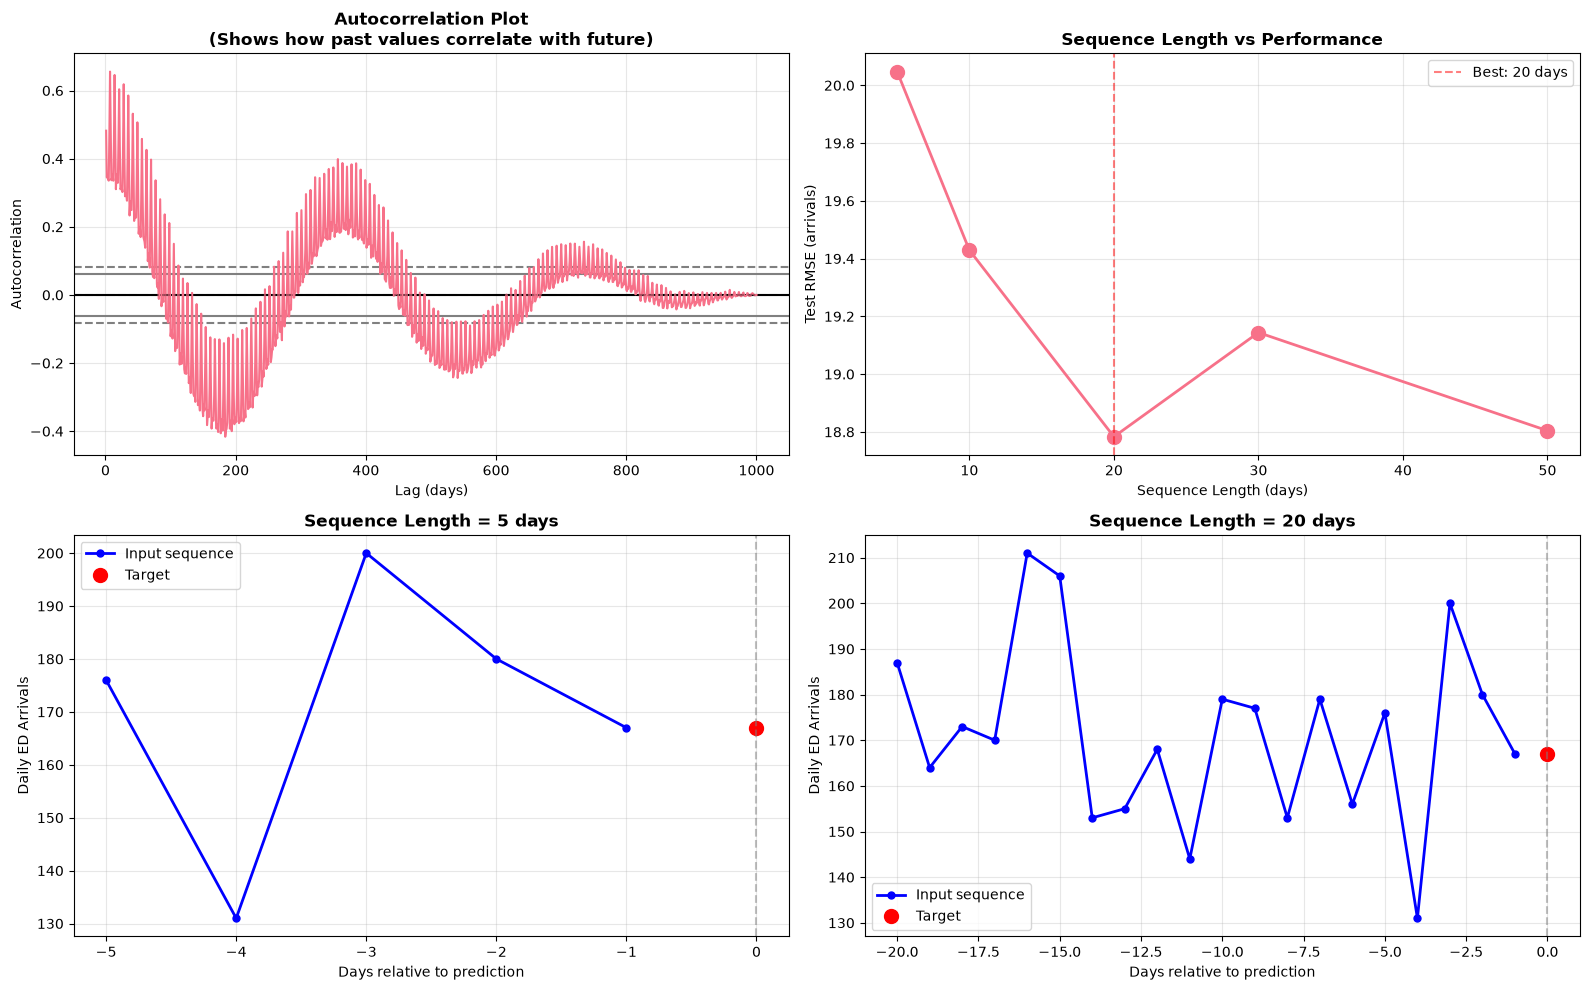


Optimal sequence length: 20 days
   Best RMSE: 18.7832 arrivals


In [17]:
# Analyze optimal sequence length
from pandas.plotting import autocorrelation_plot

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Autocorrelation plot
pd_series = pd.Series(arrivals_data)
autocorrelation_plot(pd_series, ax=axes[0, 0])
axes[0, 0].set_title('Autocorrelation Plot\n(Shows how past values correlate with future)', fontweight='bold')
axes[0, 0].set_xlabel('Lag (days)')
axes[0, 0].set_ylabel('Autocorrelation')
axes[0, 0].axhline(y=0, color='black', linestyle='--', alpha=0.3)
axes[0, 0].grid(True, alpha=0.3)

# 2. Test different sequence lengths
sequence_lengths = [5, 10, 20, 30, 50]
test_rmses_seq = []

print("Testing different sequence lengths...\n")
for seq_len in sequence_lengths:
    # Prepare data
    X_seq, y_seq = create_sequences(arrivals_normalized, seq_len)
    split = int(0.8 * len(X_seq))
    
    X_train_seq = torch.FloatTensor(X_seq[:split]).unsqueeze(-1)
    y_train_seq = torch.FloatTensor(y_seq[:split]).unsqueeze(-1)
    X_test_seq = torch.FloatTensor(X_seq[split:]).unsqueeze(-1)
    y_test_seq = torch.FloatTensor(y_seq[split:]).unsqueeze(-1)
    
    # Train model
    model_seq = LSTMModel(input_size=1, hidden_size=32, num_layers=1, output_size=1).to(device)
    _, _ = train_model(model_seq, X_train_seq, y_train_seq, X_test_seq, y_test_seq,
                      num_epochs=50, learning_rate=0.001)
    
    # Evaluate
    model_seq.eval()
    with torch.no_grad():
        preds = model_seq(X_test_seq).cpu().numpy()
    
    preds_denorm = scaler.inverse_transform(preds)
    y_actual = scaler.inverse_transform(y_seq[split:].reshape(-1, 1))
    rmse = np.sqrt(mean_squared_error(y_actual, preds_denorm))
    test_rmses_seq.append(rmse)
    
    print(f"Sequence length {seq_len:2d}: RMSE = {rmse:.4f} arrivals")

# Plot sequence length vs performance
axes[0, 1].plot(sequence_lengths, test_rmses_seq, 'o-', linewidth=2, markersize=10)
best_seq_len = sequence_lengths[np.argmin(test_rmses_seq)]
axes[0, 1].axvline(x=best_seq_len, color='red', linestyle='--', alpha=0.5, 
                   label=f'Best: {best_seq_len} days')
axes[0, 1].set_xlabel('Sequence Length (days)')
axes[0, 1].set_ylabel('Test RMSE (arrivals)')
axes[0, 1].set_title('Sequence Length vs Performance', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Visualization of different sequence lengths
example_idx = 100
for i, seq_len in enumerate([5, 20, 50]):
    if i < 2:
        ax = axes[1, i]
        ax.plot(range(-seq_len, 0), arrivals_data[example_idx-seq_len:example_idx], 
               'b-o', linewidth=2, markersize=5, label='Input sequence')
        ax.plot([0], [arrivals_data[example_idx]], 'ro', markersize=10, label='Target')
        ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
        ax.set_xlabel('Days relative to prediction')
        ax.set_ylabel('Daily ED Arrivals')
        ax.set_title(f'Sequence Length = {seq_len} days', fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

print(f"\nOptimal sequence length: {best_seq_len} days")
print(f"   Best RMSE: {min(test_rmses_seq):.4f} arrivals")

### 8.2 Handling Overfitting

RNNs are prone to overfitting. Common solutions:

1. **Dropout**: Randomly drop neurons during training
2. **Early Stopping**: Stop when validation loss stops improving
3. **Regularization**: L1/L2 weight penalties
4. **Reduce Model Complexity**: Fewer layers, smaller hidden size
5. **More Data**: Best solution when possible

Testing different dropout rates...



Epoch [20/100], Train Loss: 0.074147, Test Loss: 0.074451


Epoch [40/100], Train Loss: 0.071633, Test Loss: 0.069212


Epoch [60/100], Train Loss: 0.070383, Test Loss: 0.067675


Epoch [80/100], Train Loss: 0.070088, Test Loss: 0.067121


...

Epoch [20/100], Train Loss: 0.112940, Test Loss: 0.082005


Epoch [40/100], Train Loss: 0.075089, Test Loss: 0.068111


Epoch [60/100], Train Loss: 0.072290, Test Loss: 0.068038


Epoch [80/100], Train Loss: 0.073390, Test Loss: 0.067020


Epoch [100/100], Train Loss: 0.072466, Test Loss: 0.067316
Dropout 0.5: Train Loss = 0.072466, Test Loss = 0.067316


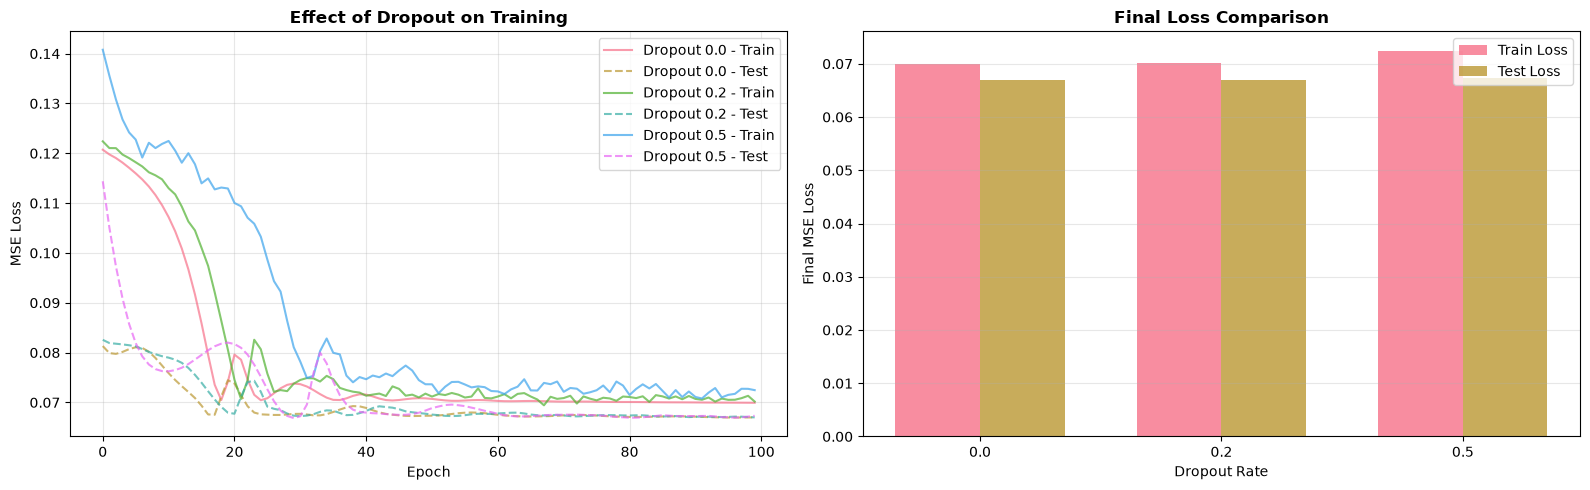


Key Insight:
  - Higher dropout -> smaller gap between train and test loss
  - But too much dropout can hurt performance
  - Typical range: 0.2-0.5 for RNNs


In [18]:
# Demonstrate dropout for regularization
class LSTMWithDropout(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1, output_size=1, dropout=0.2):
        super(LSTMWithDropout, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # LSTM with dropout
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0  # Dropout between LSTM layers
        )
        
        # Additional dropout layer
        self.dropout = nn.Dropout(dropout)
        
        # Fully connected layer
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        out, (hn, cn) = self.lstm(x, (h0, c0))
        
        # Apply dropout before final layer
        out = self.dropout(out[:, -1, :])
        out = self.fc(out)
        
        return out

# Train models with different dropout rates
dropout_rates = [0.0, 0.2, 0.5]
dropout_results = []

print("Testing different dropout rates...\n")
for dropout in dropout_rates:
    model_dropout = LSTMWithDropout(input_size=1, hidden_size=64, num_layers=2, 
                                   output_size=1, dropout=dropout).to(device)
    
    train_losses_drop, test_losses_drop = train_model(
        model_dropout, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
        num_epochs=100, learning_rate=0.001
    )
    
    dropout_results.append({
        'dropout': dropout,
        'train_losses': train_losses_drop,
        'test_losses': test_losses_drop,
        'final_train': train_losses_drop[-1],
        'final_test': test_losses_drop[-1]
    })
    
    print(f"Dropout {dropout:.1f}: Train Loss = {train_losses_drop[-1]:.6f}, Test Loss = {test_losses_drop[-1]:.6f}")

# Visualize dropout effect
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Training curves
for result in dropout_results:
    dropout = result['dropout']
    axes[0].plot(result['train_losses'], label=f'Dropout {dropout:.1f} - Train', alpha=0.7)
    axes[0].plot(result['test_losses'], label=f'Dropout {dropout:.1f} - Test', 
                linestyle='--', alpha=0.7)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].set_title('Effect of Dropout on Training', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Overfitting comparison
dropouts = [r['dropout'] for r in dropout_results]
train_losses_final = [r['final_train'] for r in dropout_results]
test_losses_final = [r['final_test'] for r in dropout_results]
overfitting_gap = [t - tr for t, tr in zip(test_losses_final, train_losses_final)]

x = np.arange(len(dropouts))
width = 0.35
axes[1].bar(x - width/2, train_losses_final, width, label='Train Loss', alpha=0.8)
axes[1].bar(x + width/2, test_losses_final, width, label='Test Loss', alpha=0.8)
axes[1].set_ylabel('Final MSE Loss')
axes[1].set_title('Final Loss Comparison', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{d:.1f}' for d in dropouts])
axes[1].set_xlabel('Dropout Rate')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(f"\nKey Insight:")
print(f"  - Higher dropout -> smaller gap between train and test loss")
print(f"  - But too much dropout can hurt performance")
print(f"  - Typical range: 0.2-0.5 for RNNs")

### 8.3 Multi-Step Forecasting

Predicting multiple future time steps (not just one).

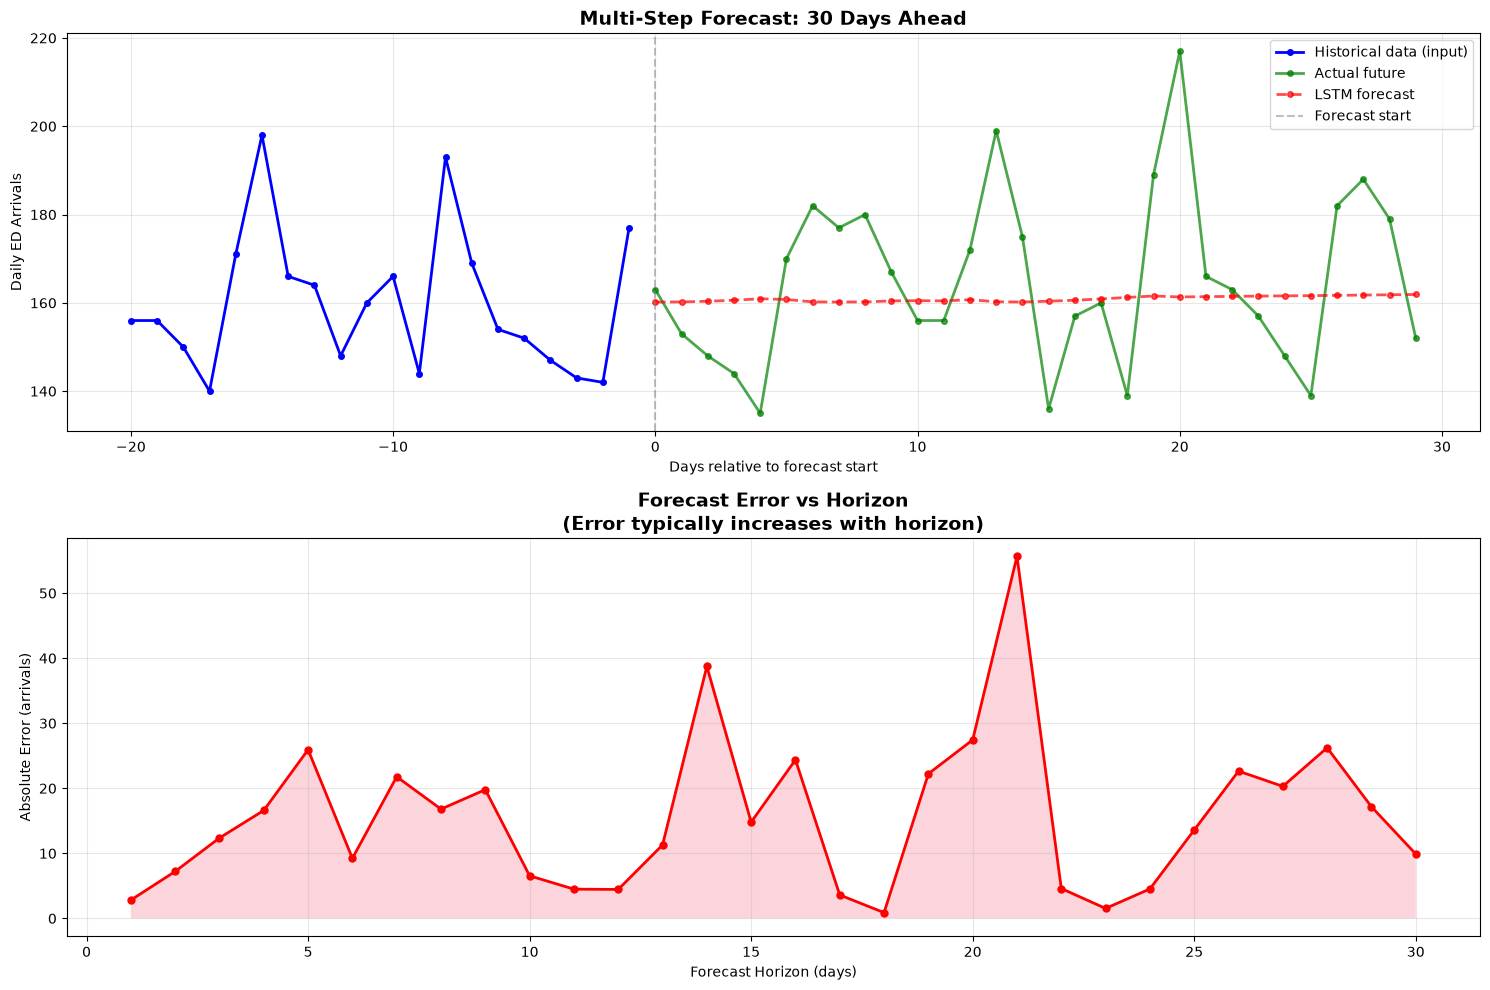


Multi-Step Forecast Performance:

   1-day forecast: MAE = 2.816 arrivals, RMSE = 2.816 arrivals
   7-day forecast: MAE = 13.706 arrivals, RMSE = 15.678 arrivals
  14-day forecast: MAE = 14.147 arrivals, RMSE = 17.125 arrivals
  30-day forecast: MAE = 15.585 arrivals, RMSE = 19.589 arrivals

Key Observation:
  - Forecast accuracy decreases with longer horizons
  - Errors accumulate as predictions feed into future predictions
  - This is normal and expected in autoregressive forecasting


In [19]:
# Multi-step ahead prediction
def multi_step_forecast(model, initial_sequence, n_steps, scaler):
    """
    Predict multiple future steps using autoregressive approach:
    - Use model to predict next step
    - Add prediction to input sequence
    - Repeat for n_steps
    """
    model.eval()
    predictions = []
    
    # Start with initial sequence
    current_sequence = initial_sequence.clone()
    
    with torch.no_grad():
        for _ in range(n_steps):
            # Predict next step
            pred = model(current_sequence)
            predictions.append(pred.cpu().numpy()[0, 0])
            
            # Update sequence: remove first element, add prediction
            current_sequence = torch.cat([
                current_sequence[:, 1:, :],
                pred.unsqueeze(1)
            ], dim=1)
    
    # Denormalize predictions
    predictions = np.array(predictions).reshape(-1, 1)
    predictions_denorm = scaler.inverse_transform(predictions)
    
    return predictions_denorm.flatten()

# Perform multi-step forecast
forecast_steps = 30  # Predict 30 days ahead
start_idx = 100  # Start from this test sample

# Get initial sequence
initial_seq = X_test_tensor[start_idx:start_idx+1, :, :]

# Make multi-step predictions with LSTM
multi_step_preds = multi_step_forecast(model_lstm, initial_seq, forecast_steps, scaler)

# Get actual values for comparison
actual_future = y_test_denorm[start_idx:start_idx+forecast_steps].flatten()

# Visualize
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Historical + forecast
hist_len = sequence_length
historical = scaler.inverse_transform(X_test[start_idx].reshape(-1, 1)).flatten()

axes[0].plot(range(-hist_len, 0), historical, 'b-o', linewidth=2, markersize=4, 
            label='Historical data (input)')
axes[0].plot(range(forecast_steps), actual_future, 'g-o', linewidth=2, markersize=4, 
            label='Actual future', alpha=0.7)
axes[0].plot(range(forecast_steps), multi_step_preds, 'r--o', linewidth=2, markersize=4, 
            label='LSTM forecast', alpha=0.7)
axes[0].axvline(x=0, color='gray', linestyle='--', alpha=0.5, label='Forecast start')
axes[0].set_xlabel('Days relative to forecast start')
axes[0].set_ylabel('Daily ED Arrivals')
axes[0].set_title(f'Multi-Step Forecast: {forecast_steps} Days Ahead', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Forecast error over time
forecast_errors = np.abs(actual_future - multi_step_preds)
axes[1].plot(range(1, forecast_steps+1), forecast_errors, 'r-o', linewidth=2, markersize=5)
axes[1].fill_between(range(1, forecast_steps+1), forecast_errors, alpha=0.3)
axes[1].set_xlabel('Forecast Horizon (days)')
axes[1].set_ylabel('Absolute Error (arrivals)')
axes[1].set_title('Forecast Error vs Horizon\n(Error typically increases with horizon)', 
                 fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate metrics at different horizons
print("\nMulti-Step Forecast Performance:\n")
for horizon in [1, 7, 14, 30]:
    if horizon <= forecast_steps:
        mae = np.mean(np.abs(actual_future[:horizon] - multi_step_preds[:horizon]))
        rmse = np.sqrt(np.mean((actual_future[:horizon] - multi_step_preds[:horizon])**2))
        print(f"  {horizon:2d}-day forecast: MAE = {mae:.3f} arrivals, RMSE = {rmse:.3f} arrivals")

print("\nKey Observation:")
print("  - Forecast accuracy decreases with longer horizons")
print("  - Errors accumulate as predictions feed into future predictions")
print("  - This is normal and expected in autoregressive forecasting")

---
## 9. Summary and Key Takeaways

### 🎯 Key Concepts:

1. **RNNs for Sequential Data**: RNNs maintain memory across time steps, making them ideal for temporal patterns

2. **Architecture Evolution**:
   - **Simple RNN**: Basic but suffers from vanishing gradients
   - **LSTM**: Solves vanishing gradients with gates and cell state
   - **GRU**: Simplified LSTM with similar performance

3. **Key Parameters**:
   - `hidden_size`: Model capacity (typically 32-512)
   - `num_layers`: Depth (1-3 for most tasks)
   - `sequence_length`: How far back to look
   - `dropout`: Regularization (0.2-0.5)

4. **Best Practices**:
   - Normalize/scale input data
   - Choose appropriate sequence length
   - Use dropout to prevent overfitting
   - Monitor train/test loss gap
   - Start with GRU, try LSTM if needed

### 🚀 When to Use RNNs:
- ✅ Time series forecasting
- ✅ Natural language processing
- ✅ Sequential decision making
- ✅ Video/audio analysis
- ❌ Tabular data without temporal structure → use XGBoost
- ❌ Very long sequences (>1000 steps) → consider Transformers

### 📚 Further Learning:
- Bidirectional RNNs (process sequence in both directions)
- Attention mechanisms
- Seq2Seq models for translation
- Transformers (modern alternative to RNNs)

### 🎓 Resources:
- [PyTorch RNN Tutorial](https://pytorch.org/tutorials/intermediate/char_rnn_classification_tutorial.html)
- [Understanding LSTM Networks](http://colah.github.io/posts/2015-08-Understanding-LSTMs/)
- [The Unreasonable Effectiveness of RNNs](http://karpathy.github.io/2015/05/21/rnn-effectiveness/)

In [20]:
# Final summary
print("RECURRENT NEURAL NETWORKS WORKSHOP COMPLETE!")
print("\nWhat We Covered:")
print("  [x] Sequential data and RNN fundamentals")
print("  [x] Vanilla RNN implementation")
print("  [x] LSTM for long-term dependencies")
print("  [x] GRU as efficient alternative")
print("  [x] Emergency department demand forecasting application")
print("  [x] Interactive parameter exploration")
print("  [x] Model comparison and evaluation")
print("  [x] Sequence length optimization")
print("  [x] Dropout for regularization")
print("  [x] Multi-step forecasting")

print("\nFinal Model Performance Summary:")
print(f"  - Simple RNN: {test_rmse:.4f} arrivals RMSE")
print(f"  - LSTM: {test_rmse_lstm:.4f} arrivals RMSE")
print(f"  - GRU: {test_rmse_gru:.4f} arrivals RMSE")

print("\nKey Takeaway:")
print("  GRU and LSTM are your go-to architectures for sequence modeling.")
print("  Start with GRU for efficiency, use LSTM if you need more capacity.")

print("\nYou're now ready to apply RNNs to your sequential data problems!")

RECURRENT NEURAL NETWORKS WORKSHOP COMPLETE!

What We Covered:
  [x] Sequential data and RNN fundamentals
  [x] Vanilla RNN implementation
  [x] LSTM for long-term dependencies
  [x] GRU as efficient alternative
  [x] Emergency department demand forecasting application
  [x] Interactive parameter exploration
  [x] Model comparison and evaluation
  [x] Sequence length optimization
  [x] Dropout for regularization
  [x] Multi-step forecasting

Final Model Performance Summary:
  - Simple RNN: 17.8190 arrivals RMSE
  - LSTM: 18.6739 arrivals RMSE
  - GRU: 18.6340 arrivals RMSE

Key Takeaway:
  GRU and LSTM are your go-to architectures for sequence modeling.
  Start with GRU for efficiency, use LSTM if you need more capacity.

You're now ready to apply RNNs to your sequential data problems!
